In [1]:
import numpy as np
import matplotlib.pyplot as plt
import imodex_miri_postprocess_pipeline as imp #homemade pipeline
from scipy.optimize import curve_fit
from astropy.stats import sigma_clip
from astropy.io import fits
import glob
from scipy.optimize import minimize
#from collections import defaultdict
import math
import glob, os
import scipy.optimize as optimize
from matplotlib.colors import LogNorm
from scipy.optimize import lsq_linear
import rdi_utils as jonas
import copy
import scipy.ndimage as nd
import time
import matplotlib.patches as patches


#ploting
import matplotlib.animation as animation
from matplotlib.animation import PillowWriter

### liste à analyser
- GJ14     : P2538 1-5 - 1140
- HD 36060 (beta pic) P1241 25-32 1140 1550 P1411 1-10 1550 2300
- HD 92945 : P1668 6-10 - 1140
- HD 106906 : P1277 19-22 - 1140 1550
- HD 107146 : P1668 1-5 - 1140
- HD 181327 : P3662
- HD 202628 : P2538 6-10 - 1140
- HD 206893 : P1668 11-15 - 1140
- HD 218396 (HR8799) : P1194 7-20 - 1065 1140 1550

In [2]:
## première version utilisant des données déjà mise en forme (200x200 + recentrage avec centre entre 4 pixels)
# nom trouvé par Jonas ^^
class ObsAML:
    def __init__(self, name, fil, pid, obssci, obsscib, obsref, obsrefb, path_data, path_bkg, path_save):
        self.name      = name
        self.fil       = "F"+str(fil)+"C"
        self.pid       = "{:05d}".format(pid)
        self.obssci    = "{:03d}".format(obssci)
        self.obsscib   = "{:03d}".format(obsscib)
        self.obsref    = "{:03d}".format(obsref)
        self.obsrefb   = "{:03d}".format(obsrefb)
        self.path_data = path_data
        self.path_bkg  = path_bkg
        self.path_save = path_save
    
        
    def quick_reduction(self):   
        
        if self.fil == "F1065C": lfil = 10.65e-6 #µm
        if self.fil == "F1140C": lfil = 11.40e-6 #µm
        if self.fil == "F1550C": lfil = 15.50e-6 #µm
        if self.fil == "F2300C": lfil = 23.00e-6 #µm
        
        
        sci_fi     = glob.glob(self.path_data+self.fil+"/P"+self.pid+"_"+self.obssci+"*_dither1_cal.fits")
        ref_fi     = glob.glob(self.path_data+self.fil+"/P"+self.pid+"_"+self.obsref+"*_dither?_cal.fits")
        sci_bkg_fi = glob.glob(self.path_bkg+self.fil+"/P"+self.pid+"_"+self.obsscib+"*_background_dither?_cal.fits")
        ref_bkg_fi = glob.glob(self.path_bkg+self.fil+"/P"+self.pid+"_"+self.obsrefb+"*_background_dither?_cal.fits")

        sci_fi.sort()
        ref_fi.sort()
        sci_bkg_fi.sort()
        ref_bkg_fi.sort()
        
        sci = fits.open(sci_fi[0])[0].data
        #sci = imp.sigma_clip_jwst(sci,3)
        imp.remove_bad_pixel(sci, 3, 5)
        sci = imp.clean_image_nan(sci)
        ref =[]
#        for i in ref_fi: ref.append(fits.open(i)[0].data)
        for i in ref_fi: ref.append(imp.clean_image_nan(imp.remove_bad_pixel(fits.open(i)[0].data,3,5)))
       ## for i in ref_fi: ref.append(imp.clean_image_nan(fits.open(i)[0].data))
        sci_bkg = np.minimum(fits.open(sci_bkg_fi[0])[0].data, fits.open(sci_bkg_fi[1])[0].data)
        ref_bkg = np.minimum(fits.open(ref_bkg_fi[0])[0].data, fits.open(ref_bkg_fi[1])[0].data)
        sci_bkg = imp.remove_bad_pixel(sci_bkg,3,5)
        sci_bkg = imp.clean_image_nan(sci_bkg)
        ref_bkg = imp.remove_bad_pixel(ref_bkg,3,5)
        ref_bkg = imp.clean_image_nan(ref_bkg)

        sci_c = sci - sci_bkg     #science - background
        ref_c = ref - ref_bkg     #reference - background

        PCA = imp.sub_PCA(sci_c, ref_c, [100,100], 2, dim=100, plot=False)
        
        path_TA = "/home/cperrot/Work/raw/JWST/Target/MAST/CAL/P"
        # flux scaling for RDI
        f_scale = imp.flux_scaling_ta(path_TA+self.pid+"/obs"+self.obssci+'/TA', path_TA+self.pid+"/obs"+self.obsref+'/TA', "cal", lfil)
        print("f_scale with TA : ",f_scale)
        RDI = imp.RDI_classic(sci_c, ref_c, f_scale=f_scale)
        RDI_1d = imp.RDI_classic(sci_c, ref_c[0,:,:], f_scale=f_scale)
        
        lcomb = imp.MIRI_linear_comb(sci_c, ref_c, use_minimize=False)
        
        imp.save_fits(PCA     , self.path_save+self.name+"_"+self.fil+"_P"+self.pid+"_"+self.obssci+"_PCA.fits")
        imp.save_fits(RDI     , self.path_save+self.name+"_"+self.fil+"_P"+self.pid+"_"+self.obssci+"_RDI.fits")
        imp.save_fits(RDI_1d  , self.path_save+self.name+"_"+self.fil+"_P"+self.pid+"_"+self.obssci+"_RDI_1d.fits")
        imp.save_fits(lcomb   , self.path_save+self.name+"_"+self.fil+"_P"+self.pid+"_"+self.obssci+"_LComb.fits")
        
        



In [ ]:
path_d = "/home/cperrot/Work/projet/JWST/Target/backgrounds/sci/"
path_b = "/home/cperrot/Work/projet/JWST/Target/backgrounds/obs/"
path_s = "/home/cperrot/Work/projet/JWST/Target/GO/lim_det/"

obs01 = ObsAML("HR8799"  , 1550, 1194, 9 , 11, 16, 18, path_d, path_b, path_s)
obs02 = ObsAML("HR8799"  , 1140, 1194, 8 , 12, 15, 19, path_d, path_b, path_s)
obs03 = ObsAML("HR8799"  , 1065, 1194, 7 , 13, 14, 20, path_d, path_b, path_s)
#1 bkg a traiter séparément
#quick_reduction_miri("beta-pic", 1065, 1241, 28, 26, 29, 31, path_d, path_b, path_s) 
#quick_reduction_miri("beta-pic", 1140, 1241, 27, 25, 30, 32, path_d, path_b, path_s)
obs04 = ObsAML("beta-pic", 1550, 1411, 4 , 1 , 8 , 9 , path_d, path_b, path_s)
obs05 = ObsAML("beta-pic", 1550, 1411, 5 , 1 , 8 , 9 , path_d, path_b, path_s)
#HD106906 - utiliser une autre ref
#quick_reduction_miri("HD106906", 1550, 1277, 20, 21, , , path_d, path_b, path_s)
obs06 = ObsAML("HD106906", 1140, 1277, 19, 22, 8 , 11, path_d, path_b, path_s)
obs07 = ObsAML("HD107146", 1140, 1668, 2 , 1 , 4 , 5 , path_d, path_b, path_s)
obs08 = ObsAML("HD107146", 1140, 1668, 3 , 1 , 4 , 5 , path_d, path_b, path_s)
obs09 = ObsAML("HD92945" , 1140, 1668, 7 , 6 , 9 , 10, path_d, path_b, path_s)
obs10 = ObsAML("HD92945" , 1140, 1668, 8 , 6 , 9 , 10, path_d, path_b, path_s)
obs11 = ObsAML("HD206893", 1140, 1668, 12, 11, 14, 15, path_d, path_b, path_s)
obs12 = ObsAML("HD206893", 1140, 1668, 13, 11, 14, 15, path_d, path_b, path_s) 
obs13 = ObsAML("HD202628", 1140, 2538, 7 , 6 , 9 , 10, path_d, path_b, path_s)
obs14 = ObsAML("HD202628", 1140, 2538, 8 , 6 , 9 , 10, path_d, path_b, path_s)
obs15 = ObsAML("GJ14"    , 1140, 2538, 2 , 1 , 4 , 5 , path_d, path_b, path_s)
obs16 = ObsAML("GJ14"    , 1140, 2538, 3 , 1 , 4 , 5 , path_d, path_b, path_s)


obs01.quick_reduction() # equivalent à ObsAML.quick_reduction(obs1)
obs02.quick_reduction()
obs03.quick_reduction()
obs04.quick_reduction()
obs05.quick_reduction()
obs06.quick_reduction()
obs07.quick_reduction()
obs08.quick_reduction()
obs09.quick_reduction()
obs10.quick_reduction()
obs11.quick_reduction()
obs12.quick_reduction()
obs13.quick_reduction()
obs14.quick_reduction()
obs15.quick_reduction()
obs16.quick_reduction()

In [2]:
# doc a faire
# fait le post processing des données corono MIRI à partir du stage 2 en RDI, PCA et CombL
class postprocess_miri_coro:
    def __init__(self, name, fil, pidsci, obssci, obsscib, pidref, obsref, obsrefb, path_data, path_save, mask_lcomb):
        self.name      = name
        self.fil       = "F"+str(fil)+"C"
        self.pids      = "{:05d}".format(pidsci)
        self.pidr      = "{:05d}".format(pidref)
        self.obssci    = "{:03d}".format(obssci)
        self.obsscib   = "{:03d}".format(obsscib)
        self.obsref    = "{:03d}".format(obsref)
        self.obsrefb   = "{:03d}".format(obsrefb)
        self.path_data = path_data
        self.path_save = path_save
        self.mask      = mask_lcomb
    
        
    def quick_reduction(self, new_dim=201, met_RDI=True, met_PCA=True, met_lcomb=True, dither=0):   
        
        if self.fil == "F1065C": 
            lam = 10.65e-6 #µm
            x0  = 120.25
            y0  = 112.03
        if self.fil == "F1140C": 
            lam = 11.40e-6 #µm
            x0  = 119.77
            y0  = 112.16
        if self.fil == "F1550C": 
            lam = 15.50e-6 #µm
            x0  = 119.71
            y0  = 113.28
        if self.fil == "F2300C": 
            lam = 23.00e-6 #µm
            x0  = 145.00
            y0  = 168.00
        
        sci_fi     = glob.glob(self.path_data+"P"+self.pids+"/obs"+self.obssci+"/P"+self.pids+"_"+self.obssci+"*_dither1_cal.fits")
        ref_fi     = glob.glob(self.path_data+"P"+self.pidr+"/obs"+self.obsref+"/P"+self.pidr+"_"+self.obsref+"*_dither?_cal.fits")
        sci_bkg_fi = glob.glob(self.path_data+"P"+self.pids+"/obs"+self.obsscib+"/P"+self.pids+"_"+self.obsscib+"*_background_dither?_cal.fits")
        ref_bkg_fi = glob.glob(self.path_data+"P"+self.pidr+"/obs"+self.obsrefb+"/P"+self.pidr+"_"+self.obsrefb+"*_background_dither?_cal.fits")

        sci_fi.sort()
        ref_fi.sort()
        sci_bkg_fi.sort()
        ref_bkg_fi.sort()
        
        sci = fits.open(sci_fi[0])[1].data
        ref = []
        for i in ref_fi: ref.append(fits.open(i)[1].data)
        ref = np.array(ref)
        sci_bkg = np.minimum(fits.open(sci_bkg_fi[0])[1].data, fits.open(sci_bkg_fi[1])[1].data)
        ref_bkg = np.minimum(fits.open(ref_bkg_fi[0])[1].data, fits.open(ref_bkg_fi[1])[1].data)
        
        sci_c = imp.clean_image_nan(imp.remove_bad_pixel(sci - sci_bkg,3,5))     #science - background
        ref_c = []
        for i in range(len(ref_fi)): ref_c.append(imp.remove_bad_pixel(ref[i,:,:] - ref_bkg,3,5))
        ref_c = np.array(ref_c)
        ref_c = imp.clean_image_nan(ref_c)
        
        sci_c = nd.shift(sci_c,[new_dim/2-y0,new_dim/2-x0])
        for i in range(len(ref_c)): ref_c[i,:,:] = nd.shift(ref_c[i,:,:],[new_dim/2-y0,new_dim/2-x0])
        sci_c = sci_c[0:new_dim,0:new_dim]
        ref_c = ref_c[:,0:new_dim,0:new_dim]
        
        if met_PCA:
            PCA = imp.sub_PCA(sci_c, ref_c, [new_dim/2,new_dim/2], 2, dim=100, plot=False)
            # PCA   = imp.remove_bad_pixel(PCA, 3,5)
            imp.save_fits(PCA  , self.path_save+self.name+"_"+self.fil+"_P"+self.pids+"_"+self.obssci+"_PCA.fits")

        if met_RDI:
            # flux scaling for RDI
            f_scale = imp.flux_scaling_ta(self.path_data+"/P"+self.pids+"/obs"+self.obssci+'/TA', self.path_data+"/P"+self.pidr+"/obs"+self.obsref+'/TA', "cal", silent=False)
            print("f_scale with TA : ",f_scale)
            RDI    = imp.RDI_classic(sci_c, ref_c, f_scale=f_scale)
            #RDI mais avec 1 seul dither (le meilleur)
            RDI_1d = imp.RDI_classic(sci_c, ref_c[dither], f_scale=f_scale)
            # RDI   = imp.remove_bad_pixel(RDI, 3,5)
            imp.save_fits(RDI   , self.path_save+self.name+"_"+self.fil+"_P"+self.pids+"_"+self.obssci+"_RDI.fits")
            imp.save_fits(RDI_1d, self.path_save+self.name+"_"+self.fil+"_P"+self.pids+"_"+self.obssci+"_RDI_1d.fits")
        
        if met_lcomb:
            lcomb = imp.MIRI_linear_comb_mask(sci_c, ref_c, self.mask, use_minimize=False)
            # lcomb = imp.remove_bad_pixel(lcomb, 3,5)
            imp.save_fits(lcomb, self.path_save+self.name+"_"+self.fil+"_P"+self.pids+"_"+self.obssci+"_LComb.fits")
        
        


In [3]:
path_d = "/home/cperrot/Work/raw/JWST/Target/MAST/CAL/"
path_s = "/home/cperrot/Work/projet/JWST/Target/GO/lim_det/"
newd = 201
Y, X = np.ogrid[:newd, :newd]

In [4]:
#Batch HR 8799

mask  = np.sqrt((X - newd/2)**2 + (Y-newd/2)**2) >= 5
mask *= np.sqrt((X - newd/2-7)**2 + (Y-newd/2-15)**2) >= 8
mask *= np.sqrt((X - newd/2-8)**2 + (Y-newd/2+3.5)**2) >= 10
mask *= np.sqrt((X - newd/2+4)**2 + (Y-newd/2+2)**2) >= 12
mask *= np.sqrt((X - newd/2-2)**2 + (Y-newd/2+3)**2) >= 5
mask *= np.sqrt((X - newd/2-22)**2 + (Y-newd/2+20)**2) >= 5
mask *= np.sqrt((X - newd/2+10)**2 + (Y-newd/2+48)**2) >= 5
mask *= np.sqrt((X - newd/2)**2 + (Y-newd/2)**2) <= 65


obs01 = postprocess_miri_coro("HR8799"  , 1550, 1194, 9 , 11, 1194, 16, 18, path_d, path_s, mask)
obs02 = postprocess_miri_coro("HR8799"  , 1140, 1194, 8 , 12, 1194, 15, 19, path_d, path_s, mask)
obs03 = postprocess_miri_coro("HR8799"  , 1065, 1194, 7 , 13, 1194, 14, 20, path_d, path_s, mask)

obs01.quick_reduction(new_dim = newd, met_RDI=False, met_PCA=False) # equivalent à postprocess_miri_coro.quick_reduction(obs1)
obs02.quick_reduction(new_dim = newd, met_RDI=False, met_PCA=False)
obs03.quick_reduction(new_dim = newd, met_RDI=False, met_PCA=False)

/home/cperrot/Work/code/JWST/Module/imodex_miri_postprocess_pipeline.py:250: RuntimeWarning: Mean of empty slice
  function=lambda x: np.nanmean(x[mask.flatten().astype(bool)]),
/home/cperrot/anaconda3/envs/jwst/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:1997: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,


In [5]:
#Batch Beta Pic

#1 bkg a traiter séparément
#quick_reduction_miri("beta-pic", 1065, 1241, 28, 26, 29, 31, path_d, path_b, path_s) 
#quick_reduction_miri("beta-pic", 1140, 1241, 27, 25, 30, 32, path_d, path_b, path_s)
mask = np.sqrt((X - newd/2)**2 + (Y-newd/2)**2) >= 10
obs04 = postprocess_miri_coro("beta-pic", 1550, 1411, 4 , 1 , 1411, 8 , 9 , path_d, path_s, mask)
obs05 = postprocess_miri_coro("beta-pic", 1550, 1411, 5 , 1 , 1411, 8 , 9 , path_d, path_s, mask)
obs04.quick_reduction(new_dim = newd, met_lcomb=False, met_PCA=False)
obs05.quick_reduction(new_dim = newd, met_lcomb=False, met_PCA=False)


f_scale with TA :  1.5376406754144123
f_scale with TA :  1.5205272974986723


In [6]:
#Batch HD106906 - pas de reference dédié, utilise une autre ref
mask  = np.sqrt((X - newd/2)**2 + (Y-newd/2)**2) >= 25
mask *= np.sqrt((X - newd/2)**2 + (Y-newd/2)**2) <= 50

obs06 = postprocess_miri_coro("HD106906", 1550, 1277, 20, 21, 1411, 8 , 9 , path_d, path_s, mask)
obs07 = postprocess_miri_coro("HD106906", 1140, 1277, 19, 22, 1277, 8 , 11, path_d, path_s, mask)

obs06.quick_reduction(new_dim = newd, met_RDI=False, met_PCA=False)
obs07.quick_reduction(new_dim = newd, met_RDI=False, met_PCA=False)

In [7]:
#Batch HD107146
 
mask  = np.sqrt((X - newd/2)**2 + (Y-newd/2)**2) >= 10
mask *= np.sqrt((X - newd/2)**2 + (Y-newd/2)**2) <= 60

obs08 = postprocess_miri_coro("HD107146", 1140, 1668, 2 , 1 , 1668, 4 , 5 , path_d, path_s, mask)
obs09 = postprocess_miri_coro("HD107146", 1140, 1668, 3 , 1 , 1668, 4 , 5 , path_d, path_s, mask)

obs08.quick_reduction(new_dim = newd, met_RDI=False, met_PCA=False)
obs09.quick_reduction(new_dim = newd, met_RDI=False, met_PCA=False)

In [8]:
#Batch HD92945

mask  = np.sqrt((X - newd/2)**2 + (Y-newd/2)**2) >= 10
mask *= np.sqrt((X - newd/2)**2 + (Y-newd/2)**2) <= 60

obs10 = postprocess_miri_coro("HD92945" , 1140, 1668, 7 , 6 , 1668, 9 , 10, path_d, path_s, mask)
obs11 = postprocess_miri_coro("HD92945" , 1140, 1668, 8 , 6 , 1668, 9 , 10, path_d, path_s, mask)

obs10.quick_reduction(new_dim = newd, met_RDI=False, met_PCA=False)
obs11.quick_reduction(new_dim = newd, met_RDI=False, met_PCA=False)

In [9]:
#Batch HD206893

mask  = np.sqrt((X - newd/2)**2 + (Y-newd/2)**2) >= 10
mask *= np.sqrt((X - newd/2)**2 + (Y-newd/2)**2) <= 60

obs12 = postprocess_miri_coro("HD206893", 1140, 1668, 12, 11, 1668, 14, 15, path_d, path_s, mask)
obs13 = postprocess_miri_coro("HD206893", 1140, 1668, 13, 11, 1668, 14, 15, path_d, path_s, mask)

obs12.quick_reduction(new_dim = newd, met_RDI=False, met_PCA=False)
obs13.quick_reduction(new_dim = newd, met_RDI=False, met_PCA=False)

In [10]:
#Batch HD202628

mask  = np.sqrt((X - newd/2)**2 + (Y-newd/2)**2) >= 10
mask *= np.sqrt((X - newd/2)**2 + (Y-newd/2)**2) <= 60

obs14 = postprocess_miri_coro("HD202628", 1140, 2538, 7 , 6 , 2538, 9 , 10, path_d, path_s, mask)
obs15 = postprocess_miri_coro("HD202628", 1140, 2538, 8 , 6 , 2538, 9 , 10, path_d, path_s, mask)

obs14.quick_reduction(new_dim = newd, met_RDI=False, met_PCA=False)
obs15.quick_reduction(new_dim = newd, met_RDI=False, met_PCA=False)

In [11]:
#Batch GJ14

mask  = np.sqrt((X - newd/2)**2 + (Y-newd/2)**2) >= 10
mask *= np.sqrt((X - newd/2)**2 + (Y-newd/2)**2) <= 60

obs16 = postprocess_miri_coro("GJ14"    , 1140, 2538, 2 , 1 , 2538, 4 , 5 , path_d, path_s, mask)
obs17 = postprocess_miri_coro("GJ14"    , 1140, 2538, 3 , 1 , 2538, 4 , 5 , path_d, path_s, mask)

obs16.quick_reduction(new_dim = newd, met_RDI=False, met_PCA=False)
obs17.quick_reduction(new_dim = newd, met_RDI=False, met_PCA=False)

In [5]:
#Batch HD 181327

mask = np.sqrt((X - newd/2)**2 + (Y-newd/2)**2) >= 21
mask *= np.sqrt((X - newd/2)**2 + (Y-newd/2)**2) <= 50

obs18 = postprocess_miri_coro("HD181327", 1140, 3662, 6 , 8 , 3662, 9 , 10 , path_d, path_s, mask)
obs19 = postprocess_miri_coro("HD181327", 1140, 3662, 7 , 8 , 3662, 9 , 10 , path_d, path_s, mask)
obs18.quick_reduction(new_dim = newd, met_lcomb=True, met_PCA=False, dither=0)
obs19.quick_reduction(new_dim = newd, met_lcomb=True, met_PCA=False, dither=0)

/home/cperrot/Work/code/JWST/Module/imodex_miri_postprocess_pipeline.py:250: RuntimeWarning: Mean of empty slice
  function=lambda x: np.nanmean(x[mask.flatten().astype(bool)]),
/home/cperrot/anaconda3/envs/jwst/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:1997: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,


f_scale with TA :  0.10161757341142456
f_scale with TA :  0.101238032269006


In [5]:
#Batch TWA 7

mask = np.sqrt((X - newd/2)**2 + (Y-newd/2)**2) >= 10
mask *= np.sqrt((X - newd/2)**2 + (Y-newd/2)**2) <= 60

obs20 = postprocess_miri_coro("TWA7", 1140, 3662, 1 , 3 , 3662, 4 , 5 , path_d, path_s, mask)
obs21 = postprocess_miri_coro("TWA7", 1140, 3662, 2 , 3 , 3662, 4 , 5 , path_d, path_s, mask)
obs20.quick_reduction(new_dim = newd, met_lcomb=True, met_PCA=True)
obs21.quick_reduction(new_dim = newd, met_lcomb=True, met_PCA=True)

/home/cperrot/Work/code/JWST/Module/imodex_miri_postprocess_pipeline.py:250: RuntimeWarning: Mean of empty slice
  function=lambda x: np.nanmean(x[mask.flatten().astype(bool)]),
/home/cperrot/anaconda3/envs/jwst/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:1997: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,


f_scale with TA :  0.4905917068330194
f_scale with TA :  0.4840297796435108


In [2]:
class lim_det_miri_coro:
    def __init__(self, name, file_name, path_data, fil, mask_obj_coord, path_save, PA_V3=0.0):
        self.name           = name
        self.file_name      = file_name
        self.fil            = "F"+str(fil)+"C"
        self.mask_obj_coord = mask_obj_coord
        self.path_data      = path_data
        self.path_save      = path_save
        self.v3i            = 4.83544897
        self.PA_V3          = PA_V3
        self.pixscale       = 0.110
        if self.fil == 'F1065C': 
            self.lam = 10.65e-6 #central wavelenght for each filter
            self.ocf = 2.0790243339681975 #open correction factor 
        if self.fil == 'F1140C': 
            self.lam = 11.40e-6
            self.ocf = 2.0887366235130878 #open correction factor 
        if self.fil == 'F1550C': 
            self.lam = 15.50e-6
            self.ocf = 2.0460859803162292 #open correction factor 
        if self.fil == 'F2300C': 
            self.lam = 23.00e-6
            self.ocf = 1.                  #open correction factor 
            
    def quick_reduction(self, saveformat, leg_name="Roll 1", showfig=False, grid=True):  
        self.saveformat = saveformat
        print(self.name)
        image = fits.open(self.path_data+self.file_name)[0].data 
        
        self.dim = np.shape(image)[0]
        x0=self.dim/2
        y0=self.dim/2
        Y, X = np.ogrid[:self.dim, :self.dim]
        scale = [(self.dim/2.)*self.pixscale,-1*(self.dim/2.)*self.pixscale,-1*(self.dim/2.)*self.pixscale,(self.dim/2.)*self.pixscale]
        
        # transmission
        path_transmission = '/home/cperrot/Work/projet/JWST/Target/Calib/transmission/'
        transmi_sum = fits.open(path_transmission+self.fil+'_transmi_sum.fits')[0].data

        ### Transmission à 45° (optimale)
        t_sum_45 = copy.deepcopy(transmi_sum)
        t_sum_45 = nd.rotate(t_sum_45, 45.-self.v3i, reshape=False)
        t_sum_45 = t_sum_45[self.dim//2,self.dim//2:]

        ### Transmission à 0° (pas optimale)
        t_sum_0 = copy.deepcopy(transmi_sum)
        t_sum_0 = nd.rotate(t_sum_0, 0.-self.v3i, reshape=False)
        t_sum_0 = t_sum_0[self.dim//2,self.dim//2:]

        ### observation at 45°
        image_45 = copy.deepcopy(image)
        image_45 = nd.rotate(image, 45-self.v3i, reshape=False)

        


        dr = 1.5*self.lam/6.5*180.*3600./np.pi/self.pixscale #pour faire une zone de 1,5*2 = 3 L/D de diametre

        transmi_cross = nd.rotate(copy.deepcopy(transmi_sum),-self.v3i, reshape=False)
        fig1 = plt.figure(figsize=(10,10))
        tmp  = plt.imshow(transmi_cross,origin='lower',cmap='inferno',interpolation='none',vmin = 0, vmax=1,extent=scale)        
        # Ajoute une ligne rouge de (0,0) à (100,100)
        plt.plot([-11, 0], [11, 0], color='red', linewidth=2)
        plt.plot([-11, 0], [0, 0], color='green', linewidth=2)
        plt.xlabel('RA [arcsec]', fontsize=16)
        plt.ylabel('DEC [arcsec]', fontsize=16)
        plt.xticks(fontsize=14)
        plt.yticks(fontsize=14)
        cbar = fig1.colorbar(tmp)
        cbar.ax.tick_params(labelsize=14)
        fig1.savefig(self.path_save+'transmission_0-45deg_illustration.'+self.saveformat,format=self.saveformat,bbox_inches='tight')
        plt.close(fig1)


        fig1 = plt.figure(figsize=(10,10))
        tmp  = plt.imshow(nd.rotate(image, 45-self.v3i, reshape=False),origin='lower',cmap='inferno',interpolation='none',vmin = np.nanmedian(image)-5*np.nanstd(image),vmax=np.nanmedian(image)+8*np.nanstd(image),extent=scale)        
        # Ajoute une ligne rouge de (0,0) à (100,100)
        plt.plot([-11, 11], [0, 0], color='white', linewidth=2)
        # Ajoute un cercle bleu centré en (50,50) avec un rayon de 20
        circle = patches.Circle((-5, 0), dr*self.pixscale, fill=True, color='blue', linewidth=2)
        ax = plt.gca()
        ax.add_patch(circle)
        plt.xlabel('RA [arcsec]', fontsize=16)
        plt.ylabel('DEC [arcsec]', fontsize=16)
        plt.xticks(fontsize=14)
        plt.yticks(fontsize=14)
        fig1.savefig(self.path_save+self.name+'_cut_illustration.'+self.saveformat,format=self.saveformat,bbox_inches='tight')
        plt.close(fig1)

        fig1 = plt.figure(figsize=(10,10))
        tmp  = plt.imshow(image,origin='lower',cmap='inferno',interpolation='none',vmin = np.nanmedian(image)-5*np.nanstd(image),vmax=np.nanmedian(image)+8*np.nanstd(image),extent=scale)        
        # Ajoute une ligne rouge de (0,0) à (100,100)
        #plt.plot([-3, 0], [0, 0], color='white', linewidth=2)
        # Ajoute un cercle bleu centré en (50,50) avec un rayon de 20
        circle = patches.Circle((-21.5*self.pixscale, -17.5*self.pixscale), 10*self.pixscale, fill=False, hatch="//", edgecolor="white", linewidth=1)
        circle_in = patches.Circle((0, 0), 3-dr*self.pixscale, fill=False, color='white', linewidth=1)
        circle_ext = patches.Circle((0, 0), 3+dr*self.pixscale, fill=False, color='white', linewidth=1)
        ax = plt.gca()
        ax.add_patch(circle)
        ax.add_patch(circle_in)
        ax.add_patch(circle_ext)
        plt.xlabel('RA [arcsec]', fontsize=16)
        plt.ylabel('DEC [arcsec]', fontsize=16)
        plt.xticks(fontsize=14)
        plt.yticks(fontsize=14)
        fig1.savefig(self.path_save+self.name+'_radial_profile_illustration.'+self.saveformat,format=self.saveformat,bbox_inches='tight')
        plt.close(fig1)

        #### masks for background objects (galaxies, stars)
        xcoord = self.mask_obj_coord[0] 
        ycoord = self.mask_obj_coord[1] 
        sizemask = self.mask_obj_coord[2] 
        
        mask_bkg_obj = np.sqrt((X - x0)**2 + (Y-y0)**2) >= 0
        for i in range(len(sizemask)): mask_bkg_obj *= (np.sqrt((X - x0 + xcoord[i])**2 + (Y - y0 + ycoord[i])**2) > sizemask[i] )

        ### Std dev local dans 3 L/D pour chaque pixel
        std_psf   = np.ndarray([self.dim,self.dim])
        for i in range(self.dim):
            for j in range(self.dim):
                mask_psf = np.sqrt((X -j)**2 + (Y -i)**2) <= dr
                std_psf[i,j] = np.nanstd(image[mask_psf])

        #image[np.where(mask_bkg_obj == 0)] = math.nan
        image[~mask_bkg_obj] = math.nan

        if showfig:
            plt.figure(figsize=(8,8))
            plt.imshow(image,origin='lower',cmap='inferno',interpolation='none',vmin = np.nanmedian(image)-5*np.nanstd(image),vmax=np.nanmedian(image)+5*np.nanstd(image),extent=scale)
            plt.show()

        mask_pla   = np.sqrt((X - x0 + 0.5)**2 + (Y - y0 + 0.5)**2)

        ### Std dev azimutale dans un anneau de 3 L/D de largeur
        std      = np.ndarray(round(np.max(mask_pla)))#self.dim//2)
        std_map  = np.ndarray([self.dim,self.dim])*0.
        for i in range(0,round(np.max(mask_pla))): #self.dim//2):
            mask_sel          = (mask_pla >= i-dr) * (mask_pla < i+dr)
            std[i]            = np.nanstd(image[mask_sel])  ### radial 
            std_map[mask_sel] = std[i]                      ### MAP based on radial lim det

        ### Calcul pour passer de 1 Sr de surface a 1 pixel de surface
        # 1 pixel = pixscale**2 in arcsec
        # 1 radian = 3600*180/pi arcsec
        # 1 sr = radian**2
        # 1 pixel in sr = (pixscale/(3600*180/np.pi))**2
        #print("1 pixel in sr = ",(pixscale/(3600*180/np.pi))**2)
        pixtosr = (self.pixscale/(3600*180/np.pi))**2 # y avait un facteur 6^2 et je sais pas pourquoi. Erreur ?
        mjytojy = 1e6                          #Mjy to µjy
        nbpixel = np.pi*dr**2                    #nombre de pixel dans la zone de photométrie de "dr" l/D de rayon 
        print("nbpixel : ",nbpixel,dr)
        coef=pixtosr*mjytojy*np.sqrt(nbpixel)*self.ocf # facteur de correction d'ouverture obtenu avec STPSF : flux in 1.5L/D / flux in the image

        ### map 5 Sigma std dev en jy par pixel avec correction de la transmission (profil radial / transmission)
        imp.save_fits(5*coef*std_map/transmi_sum,self.path_save+self.name+'_std_jy.fits')
        
        ### pareil mais en W.m-2 par pixel
        map_std_wm2 = 5*coef*imp.flux_Jy_to_Wm(self.lam*1e6,std_map)/transmi_sum
        imp.save_fits(map_std_wm2,self.path_save+self.name+'_map_std_wm2.fits')
        map_std_wm2_log = np.log10(map_std_wm2)

        fig1 = plt.figure(figsize=(10,10))
        tmp  = plt.imshow(map_std_wm2_log,origin='lower',cmap='inferno',interpolation='none',vmin = np.nanmedian(map_std_wm2_log)-5*np.nanstd(map_std_wm2_log),vmax=np.nanmedian(map_std_wm2_log)+8*np.nanstd(map_std_wm2_log),extent=scale)
        plt.title(r'Std Dev - 5$\sigma$ - '+self.fil, fontsize=20)
        plt.xlabel('RA [arcsec]', fontsize=16)
        plt.ylabel('DEC [arcsec]', fontsize=16)
        plt.xticks(fontsize=14)
        plt.yticks(fontsize=14)
        cbar = fig1.colorbar(tmp)
        cbar.set_label(r'5$\sigma$ Detection limit map [log([W.m$^{-2}.µm^{-1}$])]', fontsize=16)
        cbar.ax.tick_params(labelsize=14)
        fig1.savefig(self.path_save+self.name+'_map_std_wm2.'+self.saveformat,format=self.saveformat,bbox_inches='tight')
        plt.close(fig1)



        ### 5 sigma std dev avec zone de 3 L/D sur chaque pixel corrigé de la transmission
        local_map = 5*coef*imp.flux_Jy_to_Wm(self.lam*1e6,std_psf)/transmi_sum
        imp.save_fits(local_map,self.path_save+self.name+'_std_wm2.fits')
        ### en Jy
        local_map_jy = 5*coef*std_psf/transmi_sum
        imp.save_fits(local_map_jy,self.path_save+self.name+'_std_jy.fits')

        
        local_map_log = np.log10(local_map)

        fig1 = plt.figure(figsize=(10,10))
        tmp  = plt.imshow(local_map_log,origin='lower',cmap='inferno',interpolation='none',vmin = np.nanmedian(local_map_log)-5*np.nanstd(local_map_log),vmax=np.nanmedian(local_map_log)+8*np.nanstd(local_map_log),extent=scale)
        plt.title(r'Std Dev - 5$\sigma$ - '+self.fil, fontsize=20)
        plt.xlabel('RA [arcsec]', fontsize=16)
        plt.ylabel('DEC [arcsec]', fontsize=16)
        plt.xticks(fontsize=14)
        plt.yticks(fontsize=14)
        cbar = fig1.colorbar(tmp)
        cbar.set_label(r'5$\sigma$ Detection limit map [log([W.m$^{-2}.µm^{-1}$])]', fontsize=16)
        cbar.ax.tick_params(labelsize=14)
        fig1.savefig(self.path_save+self.name+'_std_wm2.'+self.saveformat,format=self.saveformat,bbox_inches='tight')
        plt.close(fig1)

        #with rotation
        local_map_log = nd.rotate(np.log10(local_map), -self.PA_V3-self.v3i, reshape=True, mode="constant", cval = math.nan )
        local_map_jy_log = nd.rotate(np.log10(local_map_jy), -self.PA_V3-self.v3i, reshape=True, mode="constant", cval = math.nan )
        self.local_map_log = local_map_log
        self.local_map_jy_log = local_map_jy_log
        rot_dim = np.shape(local_map_log)
        rot_scale = [(rot_dim[0]/2.)*self.pixscale,-1*(rot_dim[0]/2.)*self.pixscale,-1*(rot_dim[1]/2.)*self.pixscale,(rot_dim[1]/2.)*self.pixscale]
        fig1 = plt.figure(figsize=(10,10))
        tmp  = plt.imshow(local_map_log,origin='lower',cmap='inferno',interpolation='none',vmin = -21, vmax = -17 ,extent=rot_scale)
        #plt.title(r'Std Dev - 5$\sigma$ - '+self.fil, fontsize=20)
        plt.xlabel('RA [arcsec]', fontsize=16)
        plt.ylabel('DEC [arcsec]', fontsize=16)
        plt.xticks(fontsize=14)
        plt.yticks(fontsize=14)
        cbar = fig1.colorbar(tmp)
        cbar.set_label(r'5$\sigma$ Detection limit map [log([W.m$^{-2}.µm^{-1}$])]', fontsize=16)
        cbar.ax.tick_params(labelsize=14)
        fig1.savefig(self.path_save+self.name+'_std_wm2_rot.'+self.saveformat,format=self.saveformat,bbox_inches='tight')
        plt.close(fig1)


        ### passage de Jy a W/m2/µm
        std_wm   = imp.flux_Jy_to_Wm(self.lam*1e6,std)

        lim_det_5sig_t0_wm  = np.ndarray(self.dim//2)
        file = open(self.path_save+"lim_det_wm2_"+self.name+"_"+self.fil+"_0deg.dat","w")
        for i in range(0,self.dim//2):
            lim_det_5sig_t0_wm[i]  = 5*coef*std_wm[i]/t_sum_0[i]
            file.write("{:4.3f}".format(i*self.pixscale)+" {:.3e}".format(lim_det_5sig_t0_wm[i])+"\n")
        file.close()

        lim_det_5sig_t45_wm = np.ndarray(self.dim//2)
        file = open(self.path_save+"lim_det_wm2_"+self.name+"_"+self.fil+"_45deg.dat","w")
        for i in range(0,self.dim//2):
            lim_det_5sig_t45_wm[i] = 5*coef*std_wm[i]/t_sum_45[i]
            file.write("{:4.3f}".format(i*self.pixscale)+" {:.3e}".format(lim_det_5sig_t45_wm[i])+"\n")
        file.close()

        # Lim de det en Jy
        file = open(self.path_save+"lim_det_jy_"+self.name+"_"+self.fil+"_0deg.dat","w")
        for i in range(0,self.dim//2):
            file.write("{:4.3f}".format(i*self.pixscale)+" {:.3e}".format(5*coef*std[i]/t_sum_0[i])+"\n")
        file.close()

        file = open(self.path_save+"lim_det_jy_"+self.name+"_"+self.fil+"_45deg.dat","w")
        for i in range(0,self.dim//2):
            file.write("{:4.3f}".format(i*self.pixscale)+" {:.3e}".format(5*coef*std[i]/t_sum_45[i])+"\n")
        file.close()



        t_sum_45_bis = copy.deepcopy(transmi_sum)
        t_sum_45_bis = nd.rotate(t_sum_45_bis, 45.-self.v3i, reshape=False)
        t_sum_45_bis = t_sum_45_bis[self.dim//2,:]
        std_45       = np.ndarray(self.dim)
        tmp_mask_psf = np.ndarray([self.dim,self.dim,self.dim])
        for i in range(self.dim):
            mask_psf = np.sqrt((X -i)**2 + (Y-self.dim//2)**2) <= dr
            tmp_mask_psf[i,:,:] = mask_psf
            std_45[i] = 5*coef*imp.flux_Jy_to_Wm(self.lam*1e6,np.nanstd(image_45[mask_psf]))/t_sum_45_bis[i]


        fig1 = plt.figure(figsize=(10,7))
        plt.plot(np.arange(0,self.dim//2,1)*0.11,lim_det_5sig_t45_wm,'green',label=leg_name+" - 45°")
        plt.plot(np.arange(0,self.dim//2,1)*0.11,lim_det_5sig_t0_wm,'red',label=leg_name+" - 0°")
        plt.title(r'Std Dev - 5$\sigma$ - '+self.fil, fontsize=20)
        plt.xlabel('Separation [arcsec]', fontsize=16)
        plt.ylabel(r'5$\sigma$ Detection limit [W.m$^{-2}.µm^{-1}$]', fontsize=16)
        plt.yscale('log')
        if grid:
            plt.grid(True, which="major", ls="-")
            plt.grid(True, which="minor", ls="--")
        plt.ylim([1e-20,1e-16])
        plt.xlim([0,11])
        plt.xticks(fontsize=14)
        plt.yticks(fontsize=14)
        plt.legend(fontsize=14)
        fig1.savefig(self.path_save+self.name+'_stddev_wm2.'+self.saveformat,format=self.saveformat,bbox_inches='tight')
        plt.close(fig1)

        self.lim_det_5sig_t45_wm = lim_det_5sig_t45_wm
        self.lim_det_5sig_t0_wm = lim_det_5sig_t0_wm

        fig1 = plt.figure(figsize=(10,7))
        plt.plot(np.arange(0,self.dim//2,1)*0.11,std_45[0:self.dim//2][::-1],'blue',label=leg_name+" - 45° cut +")
        plt.plot(np.arange(0,self.dim//2,1)*0.11,std_45[self.dim//2+1:],'red',label=leg_name+" - 45° cut -")
        plt.title(r'Std Dev - 5$\sigma$ - '+self.fil, fontsize=20)
        plt.xlabel('Separation [arcsec]', fontsize=16)
        plt.ylabel(r'5$\sigma$ Detection limit [W.m$^{-2}.µm^{-1}$]', fontsize=16)
        plt.yscale('log')
        if grid:
            plt.grid(True, which="major", ls="-")
            plt.grid(True, which="minor", ls="--")
        plt.ylim([1e-20,1e-16])
        plt.xlim([0,11])
        plt.xticks(fontsize=14)
        plt.yticks(fontsize=14)
        plt.legend(fontsize=14)
        fig1.savefig(self.path_save+self.name+'_stddev_cut_wm2.'+self.saveformat,format=self.saveformat,bbox_inches='tight')
        plt.close(fig1)
        
      



In [3]:
path_d = "/home/cperrot/Work/projet/JWST/Target/GO/lim_det/"
path_s = "/home/cperrot/Work/projet/JWST/Target/GO/lim_det/"
saveformat = "pdf"

In [8]:
mask_obj = [[-21,72,-6,-9,5],[18,-12,-14,5,3],[10,10,3,3,3]]
lim1 = lim_det_miri_coro("HR8799_obs009", "HR8799_F1550C_P01194_009_LComb.fits", path_d, 1550, mask_obj, path_s)
mask_obj = [[-21,72,-6,-9,5,-2,10,43],[18,-12,-14,5,3,3,47,73],[3,10,6,5,5,4,3,4]]
lim2 = lim_det_miri_coro("HR8799_obs008", "HR8799_F1140C_P01194_008_LComb.fits", path_d, 1140, mask_obj, path_s)
mask_obj = [[-21,72,-6,-9,5,-2,10,43,-43],[18,-12,-14,5,3,3,47,73,44],[3,10,6,5,5,4,6,4,5]]
lim3 = lim_det_miri_coro("HR8799_obs007", "HR8799_F1065C_P01194_007_LComb.fits", path_d, 1065, mask_obj, path_s)

lim1.quick_reduction(saveformat)
lim2.quick_reduction(saveformat)
lim3.quick_reduction(saveformat)

HR8799_obs009
HR8799_obs008
HR8799_obs007


In [9]:

#1 bkg a traiter séparément
#quick_reduction_miri("beta-pic", 1065, 1241, 28, 26, 29, 31, path_d, path_b, path_s) 
#quick_reduction_miri("beta-pic", 1140, 1241, 27, 25, 30, 32, path_d, path_b, path_s)

mask_obj = [[48],[+22],[0]] ### a vérifier
lim4 = lim_det_miri_coro("beta-pic_obs004", "beta-pic_F1550C_P01411_004_RDI.fits", path_d, 1550, mask_obj, path_s) #roll 1 
lim5 = lim_det_miri_coro("beta-pic_obs005", "beta-pic_F1550C_P01411_005_RDI.fits", path_d, 1550, mask_obj, path_s) #roll 2

lim4.quick_reduction(saveformat, leg_name="Roll 1")
lim5.quick_reduction(saveformat, leg_name="Roll 2")  

beta-pic_obs004
beta-pic_obs005


In [10]:
#HD106906
mask_obj = [[-55],[35],[10]] 
lim6 = lim_det_miri_coro("HD106906_obs020", "HD106906_F1550C_P01277_020_LComb.fits", path_d, 1140, mask_obj, path_s)
lim7 = lim_det_miri_coro("HD106906_obs019", "HD106906_F1140C_P01277_019_LComb.fits", path_d, 1140, mask_obj, path_s)

lim6.quick_reduction(saveformat)
lim7.quick_reduction(saveformat)

HD106906_obs020
HD106906_obs019


In [11]:
mask_obj = [[32,32,32,-17],[-6,-12,0,-14],[5,5,5,3]] 
lim8 = lim_det_miri_coro("HD107146_obs002", "HD107146_F1140C_P01668_002_LComb.fits", path_d, 1140, mask_obj, path_s) #roll 1 
mask_obj = [[33,32,-17,-56],[1,-8,-15,-56],[5,5,3,3]] 
lim9 = lim_det_miri_coro("HD107146_obs003", "HD107146_F1140C_P01668_003_LComb.fits", path_d, 1140, mask_obj, path_s) #roll 2 

lim8.quick_reduction(saveformat, leg_name="Roll 1")
lim9.quick_reduction(saveformat, leg_name="Roll 2")

HD107146_obs002
HD107146_obs003


In [12]:
mask_obj = [[54,36,12,-17,-57,-80],[15,31,48,-14,-57,70],[3,3,7,3,3,12]] 
lim10 = lim_det_miri_coro("HD92945_obs007", "HD92945_F1140C_P01668_007_LComb.fits", path_d, 1140, mask_obj, path_s) #roll 1
mask_obj = [[55,39,18,-17,-57,-71],[8,27,47,-14,-55,79],[3,3,7,3,3,12]] 
lim11 = lim_det_miri_coro("HD92945_obs008", "HD92945_F1140C_P01668_008_LComb.fits", path_d, 1140, mask_obj, path_s) #roll 2

lim10.quick_reduction(saveformat, leg_name="Roll 1")
lim11.quick_reduction(saveformat, leg_name="Roll 2")

HD92945_obs007
HD92945_obs008


In [13]:
mask_obj = [[-17,-57,95,35,-78,42],[-14,-57,29,47,-72,-95],[3,3,5,5,15,10]] 
lim12 = lim_det_miri_coro("HD206893_obs012", "HD206893_F1140C_P01668_012_LComb.fits", path_d, 1140, mask_obj, path_s) #roll 1
mask_obj = [[-17,-57,91,29,-69],[-14,-57,41,52,-80],[3,3,5,5,15]] 
lim13 = lim_det_miri_coro("HD206893_obs013", "HD206893_F1140C_P01668_013_LComb.fits", path_d, 1140, mask_obj, path_s) #roll 2

lim12.quick_reduction(saveformat, leg_name="Roll 1")
lim13.quick_reduction(saveformat, leg_name="Roll 2")

HD206893_obs012
HD206893_obs013


In [14]:
mask_obj = [[-17,-57,-16,91,17,27,-73],[-14,-57,-95,-89,10,5,41],[3,3,3,3,5,5,5]] 
lim14 = lim_det_miri_coro("HD202628_obs007", "HD202628_F1140C_P02538_007_LComb.fits", path_d, 1140, mask_obj, path_s) #roll 1
mask_obj = [[-17,-57,0,15,9,-74],[-14,-57,-97,12,17,41],[3,3,3,5,5,6]] 
lim15 = lim_det_miri_coro("HD202628_obs008", "HD202628_F1140C_P02538_008_LComb.fits", path_d, 1140, mask_obj, path_s) #roll 2

lim14.quick_reduction(saveformat, leg_name="Roll 1")
lim15.quick_reduction(saveformat, leg_name="Roll 2")

HD202628_obs007
HD202628_obs008


In [15]:
mask_obj = [[-17,-57,-15,-7,-30,56,-64,57],[-14,-57,11,-45,-35,5,50,85],[3,3,3,3,5,3,3,3]] 
lim16 = lim_det_miri_coro("GJ14_obs002", "GJ14_F1140C_P02538_002_LComb.fits", path_d, 1140, mask_obj, path_s) #roll 1
lim17 = lim_det_miri_coro("GJ14_obs003", "GJ14_F1140C_P02538_003_LComb.fits", path_d, 1140, mask_obj, path_s) #roll 2

lim16.quick_reduction(saveformat, leg_name="Roll 1")
lim17.quick_reduction(saveformat, leg_name="Roll 2")

GJ14_obs002
GJ14_obs003


In [4]:
mask_obj = [[50,39,28,52,-66],[63,63,63,-16,-42],[8,8,8,8,6]] 
lim18 = lim_det_miri_coro("HD181327_obs006", "HD181327_F1140C_P03662_006_RDI_1d.fits", path_d, 1140, mask_obj, path_s, PA_V3=59.5885) #roll 1
mask_obj = [[58,47,36,50,-71],[58,59,60,-20,-34],[8,8,8,8,6]] 
lim19 = lim_det_miri_coro("HD181327_obs007", "HD181327_F1140C_P03662_007_RDI_1d.fits", path_d, 1140, mask_obj, path_s, PA_V3=66.596) #roll 2

lim18.quick_reduction(saveformat, leg_name="Roll 1")
lim19.quick_reduction(saveformat, leg_name="Roll 2")








HD181327_obs006
nbpixel :  76.4504905131289 4.933046415140347
HD181327_obs007
nbpixel :  76.4504905131289 4.933046415140347


HD181327_obs007_margot
nbpixel :  76.4504905131289 4.933046415140347


/tmp/ipykernel_19798/2348787418.py:160: RuntimeWarning: divide by zero encountered in log10
  map_std_wm2_log = np.log10(map_std_wm2)
/home/cperrot/anaconda3/envs/jwst/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:1845: RuntimeWarning: invalid value encountered in subtract
  np.subtract(arr, avg, out=arr, casting='unsafe', where=where)
/tmp/ipykernel_19798/2348787418.py:185: RuntimeWarning: divide by zero encountered in log10
  local_map_log = np.log10(local_map)
/home/cperrot/anaconda3/envs/jwst/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:1845: RuntimeWarning: invalid value encountered in subtract
  np.subtract(arr, avg, out=arr, casting='unsafe', where=where)
/tmp/ipykernel_19798/2348787418.py:201: RuntimeWarning: divide by zero encountered in log10
  local_map_log = nd.rotate(np.log10(local_map), -self.PA_V3-self.v3i, reshape=True, mode="constant", cval = math.nan )
/tmp/ipykernel_19798/2348787418.py:202: RuntimeWarning: divide by zero encountered in 

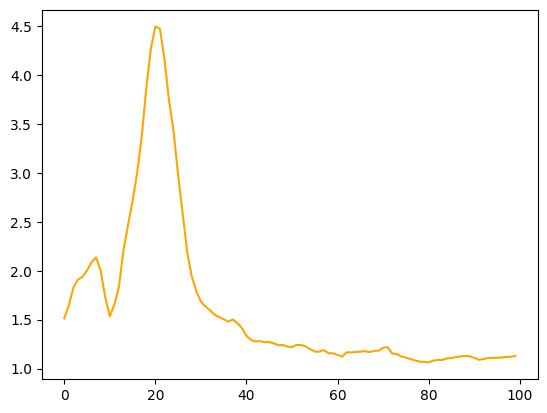

In [15]:


image = fits.open(path_d+"MIRI_HD181327_residual_maps_2belts_minchi2_mid_mask.fits")[0].data         
dim = np.shape(image)[0]

image = np.pad(image, pad_width=1, mode='reflect')
image = image[:-1, :-1]

image = nd.shift(image ,[-0.5,-0.5])
image = nd.rotate(image, 66.596+4.83544897, reshape=False)
imp.save_fits(image,path_d+"MIRI_HD181327_residual_maps_2belts_minchi2_mid_mask_201x201.fits")

mask_obj = [[58,47,36,50,-71],[58,59,60,-20,-34],[8,8,8,8,6]] 
lim19m = lim_det_miri_coro("HD181327_obs007_margot", "MIRI_HD181327_residual_maps_2belts_minchi2_mid_mask_201x201.fits", path_d, 1140, mask_obj, path_s, PA_V3=66.596) #roll 2
lim19m.quick_reduction(saveformat, leg_name="Margot Roll 2",showfig=False)

plt.plot(lim19.lim_det_5sig_t45_wm/lim19m.lim_det_5sig_t45_wm,color="orange")
plt.show()


HD181327_obs007_single
nbpixel :  76.4504905131289 4.933046415140347


/tmp/ipykernel_66227/2348787418.py:160: RuntimeWarning: divide by zero encountered in log10
  map_std_wm2_log = np.log10(map_std_wm2)
/home/cperrot/anaconda3/envs/jwst/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:1845: RuntimeWarning: invalid value encountered in subtract
  np.subtract(arr, avg, out=arr, casting='unsafe', where=where)
/tmp/ipykernel_66227/2348787418.py:185: RuntimeWarning: divide by zero encountered in log10
  local_map_log = np.log10(local_map)
/home/cperrot/anaconda3/envs/jwst/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:1845: RuntimeWarning: invalid value encountered in subtract
  np.subtract(arr, avg, out=arr, casting='unsafe', where=where)
/tmp/ipykernel_66227/2348787418.py:201: RuntimeWarning: divide by zero encountered in log10
  local_map_log = nd.rotate(np.log10(local_map), -self.PA_V3-self.v3i, reshape=True, mode="constant", cval = math.nan )
/tmp/ipykernel_66227/2348787418.py:202: RuntimeWarning: divide by zero encountered in 

HD181327_obs007_residu
nbpixel :  76.4504905131289 4.933046415140347


/tmp/ipykernel_66227/2348787418.py:160: RuntimeWarning: divide by zero encountered in log10
  map_std_wm2_log = np.log10(map_std_wm2)
/home/cperrot/anaconda3/envs/jwst/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:1845: RuntimeWarning: invalid value encountered in subtract
  np.subtract(arr, avg, out=arr, casting='unsafe', where=where)
/tmp/ipykernel_66227/2348787418.py:185: RuntimeWarning: divide by zero encountered in log10
  local_map_log = np.log10(local_map)
/home/cperrot/anaconda3/envs/jwst/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:1845: RuntimeWarning: invalid value encountered in subtract
  np.subtract(arr, avg, out=arr, casting='unsafe', where=where)
/tmp/ipykernel_66227/2348787418.py:201: RuntimeWarning: divide by zero encountered in log10
  local_map_log = nd.rotate(np.log10(local_map), -self.PA_V3-self.v3i, reshape=True, mode="constant", cval = math.nan )
/tmp/ipykernel_66227/2348787418.py:202: RuntimeWarning: divide by zero encountered in 

HD181327_obs007_margot
nbpixel :  76.4504905131289 4.933046415140347


/tmp/ipykernel_66227/2348787418.py:160: RuntimeWarning: divide by zero encountered in log10
  map_std_wm2_log = np.log10(map_std_wm2)
/home/cperrot/anaconda3/envs/jwst/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:1845: RuntimeWarning: invalid value encountered in subtract
  np.subtract(arr, avg, out=arr, casting='unsafe', where=where)
/tmp/ipykernel_66227/2348787418.py:185: RuntimeWarning: divide by zero encountered in log10
  local_map_log = np.log10(local_map)
/home/cperrot/anaconda3/envs/jwst/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:1845: RuntimeWarning: invalid value encountered in subtract
  np.subtract(arr, avg, out=arr, casting='unsafe', where=where)
/tmp/ipykernel_66227/2348787418.py:201: RuntimeWarning: divide by zero encountered in log10
  local_map_log = nd.rotate(np.log10(local_map), -self.PA_V3-self.v3i, reshape=True, mode="constant", cval = math.nan )
/tmp/ipykernel_66227/2348787418.py:202: RuntimeWarning: divide by zero encountered in 

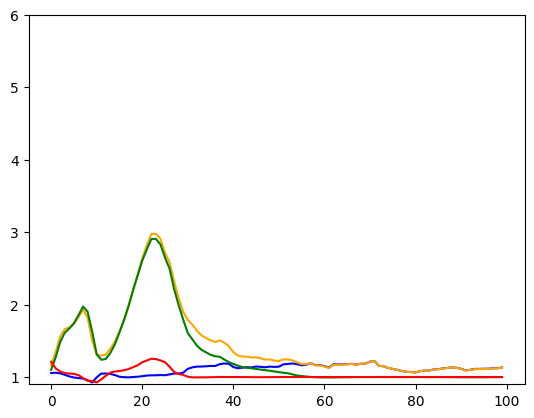

In [14]:
## investigation sur les différence entre les données de Margot et les miennes. réponse : "prefilter = False " filtre les donnees, il ne faut pas le mettre
image = fits.open(path_d+"image_single_F1140C_roll2.fits")[0].data         
model = fits.open(path_d+"MIRI_HD181327_DDIT_1p0-50um_STPSF_25_3_2_88_10_1_bestmodel_chi2.fits")[1].data         
residu = image-model

dim = np.shape(image)[0]

image = np.pad(image, pad_width=1, mode='reflect')
image = image[:-1, :-1]
image = nd.shift(image ,[-0.5,-0.5])#, prefilter=False) 
image = nd.rotate(image, 66.596+4.83544897, reshape=False)#, prefilter=False)
imp.save_fits(image,path_d+"image_single_F1140C_roll2_201x201.fits")

model = np.pad(model, pad_width=1, mode='reflect')
model = model[:-1, :-1]
model = nd.shift(model ,[-0.5,-0.5])#, prefilter=False) 
model = nd.rotate(model, 66.596+4.83544897, reshape=False)#, prefilter=False)
imp.save_fits(model,path_d+"best_model_margot_201x201.fits")

residu = np.pad(residu, pad_width=1, mode='reflect')
residu = residu[:-1, :-1]
residu = nd.shift(residu ,[-0.5,-0.5])#, prefilter=False) 
residu = nd.rotate(residu, 66.596+4.83544897, reshape=False)# prefilter=False)
imp.save_fits(residu,path_d+"residu_margot_201x201.fits")


mask_obj = [[58,47,36,50,-71],[58,59,60,-20,-34],[8,8,8,8,6]] 
lim19s = lim_det_miri_coro("HD181327_obs007_single", "image_single_F1140C_roll2_201x201.fits", path_d, 1140, mask_obj, path_s, PA_V3=66.596) #roll 2
lim19s.quick_reduction(saveformat, leg_name="Single Roll 2",showfig=False)

mask_obj = [[58,47,36,50,-71],[58,59,60,-20,-34],[8,8,8,8,6]] 
lim19m = lim_det_miri_coro("HD181327_obs007_residu", "residu_margot_201x201.fits", path_d, 1140, mask_obj, path_s, PA_V3=66.596) #roll 2
lim19m.quick_reduction(saveformat, leg_name="Single Roll 2",showfig=False)

mask_obj = [[58,47,36,50,-71],[58,59,60,-20,-34],[8,8,8,8,6]] 
lim19mm = lim_det_miri_coro("HD181327_obs007_margot", "residual_maps_1um_2belts_201x201.fits", path_d, 1140, mask_obj, path_s, PA_V3=66.596) #roll 2
lim19mm.quick_reduction(saveformat, leg_name="Margot Roll 2",showfig=False)


plt.plot(lim19.lim_det_5sig_t45_wm/lim19s.lim_det_5sig_t45_wm,color="blue",label="")
plt.plot(lim19.lim_det_5sig_t45_wm/lim19m.lim_det_5sig_t45_wm,color="orange")
plt.plot(lim19s.lim_det_5sig_t45_wm/lim19m.lim_det_5sig_t45_wm,color="green")
plt.plot(lim19m.lim_det_5sig_t45_wm/lim19mm.lim_det_5sig_t45_wm,color="red")
plt.ylim(0.9,6)
plt.show()

In [16]:
### plot special papier de Margot
fig1 = plt.figure(figsize=(10,8.2))
ax1 = plt.gca()  # Récupère l'axe principal
#ax1.plot(np.arange(0,lim18.dim//2,1)*0.11,imp.flux_Wm_to_Jy(lim18.lam*1e6,lim18.lim_det_5sig_t45_wm)*1e6,color='green',label="Roll 1 - Best case")
#ax1.plot(np.arange(0,lim18.dim//2,1)*0.11,imp.flux_Wm_to_Jy(lim18.lam*1e6,lim18.lim_det_5sig_t0_wm)*1e6,'--',color='green', label="Roll 1 - Worst case")
#ax1.plot(np.arange(0,lim19.dim//2,1)*0.11,imp.flux_Wm_to_Jy(lim19.lam*1e6,lim19.lim_det_5sig_t45_wm)*1e6,color='red',label="Roll 2 - Best case")
#ax1.plot(np.arange(0,lim19.dim//2,1)*0.11,imp.flux_Wm_to_Jy(lim19.lam*1e6,lim19.lim_det_5sig_t0_wm)*1e6,'--',color='red', label="Roll 2 - Worst case")
ax1.plot(np.arange(0,lim19m.dim//2,1)*0.11,imp.flux_Wm_to_Jy(lim19m.lam*1e6,lim19m.lim_det_5sig_t45_wm)*1e6,color='black',label="Residual - Best case")
ax1.plot(np.arange(0,lim19m.dim//2,1)*0.11,imp.flux_Wm_to_Jy(lim19m.lam*1e6,lim19m.lim_det_5sig_t0_wm)*1e6,'--',color='black',label="Residual - Worst case")
ax1.errorbar([62/47.7],[1.9e-5*1e6],[[0.6e1],[0.9e1]],[0],'o',capsize=5,color="blue",label=r"1$M_J$ planet flux")
ax1.plot([0,5],[1.9e-5*1e6,1.9e-5*1e6],'-',color='blue')
ax1.errorbar([62/47.7],[2.7e-5*1e6],[[1.0e1],[1.5e1]],[0],'o',capsize=5,color="red",label=r"2$M_J$ planet flux")
ax1.plot([0,5],[2.7e-5*1e6,2.7e-5*1e6],'-',color='red')
ax1.errorbar([62/47.7],[9.6e-5*1e6],[[2.5e1],[4.8e1]],[0],'o',capsize=5,color="green",label=r"5$M_J$ planet flux")
ax1.plot([0,5],[9.6e-5*1e6,9.6e-5*1e6],'-',color='green')
ax1.errorbar([62/47.7],[22.e-5*1e6],[[8.0e1],[12.e1]],[0],'o',capsize=5,color="orange",label=r"10$M_J$ planet flux")
ax1.plot([0,5],[22.e-5*1e6,22.e-5*1e6],'-',color='orange')
plt.title(r'5$\sigma$ Detection limit', fontsize=20)
ax1.set_xlabel('Separation [arcsec]', fontsize=16)
ax1.set_yscale('log')
#plt.grid(True, which="major", ls="-") 
#plt.grid(True, which="minor", ls="--")
ax1.set_xlim([0,5])
ax1.set_xticks(np.linspace(0, 5, 11))
plt.tick_params(labelsize=14)
ax2 = ax1.twinx()  # Crée un axe jumeau partageant l'axe X
ax2.set_ylim([1e-20,1e-16])
ax2.set_ylabel(r'[W.m$^{-2}.µm^{-1}$]', fontsize=16)
ax2.plot(np.arange(0,lim19.dim//2,1)*0.11,lim19.lim_det_5sig_t45_wm, color='blue', alpha=0) 
ax1.set_ylabel(r'[µJy]', fontsize=16)
ax2.set_yscale('log')
ax1.set_ylim([imp.flux_Wm_to_Jy(lim19.lam*1e6,1e-20)*1e6, imp.flux_Wm_to_Jy(lim19.lam*1e6,1e-16)*1e6])  # Ajuste les limites en Jy
ax1.legend(fontsize=14)
plt.tick_params(labelsize=14)
fig1.savefig(lim19.path_save+lim19.name+'_stddev_wm2_2rolls.'+lim19.saveformat,format=lim19.saveformat,bbox_inches='tight')
plt.close(fig1)


#with rotation
dim1 = np.shape(lim18.local_map_jy_log )
dim2 = np.shape(lim19.local_map_jy_log )

roll1 = lim18.local_map_jy_log+6.
roll2 = np.ndarray((np.shape(roll1)[0],np.shape(roll1)[1]))

tmp_map = lim19.local_map_jy_log+6.
tmp_map[np.isnan(tmp_map)] = 0
roll2[dim1[0]//2-dim2[0]//2:dim1[0]//2+dim2[0]//2+1, dim1[1]//2-dim2[1]//2:dim1[1]//2+dim2[1]//2+1] = nd.shift(tmp_map ,[-0.5,-0.5], prefilter=False) 

rot_dim = np.shape(roll1)
rot_scale = [(rot_dim[0]/2.)*lim19.pixscale,-1*(rot_dim[0]/2.)*lim19.pixscale,-1*(rot_dim[1]/2.)*lim19.pixscale,(rot_dim[1]/2.)*lim19.pixscale]

fig1 = plt.figure(figsize=(7,7))
#tmp  = plt.imshow(roll1,origin='lower',cmap='inferno',interpolation='none',vmin = -20, vmax = -17 ,extent=rot_scale)
#tmp  = plt.imshow(roll2,origin='lower',cmap='inferno',interpolation='none',vmin = -20, vmax = -17 ,extent=rot_scale)
tmp  = plt.imshow(np.minimum(roll1,roll2),origin='lower',cmap='viridis',interpolation='none',vmin = 0, vmax = 3 ,extent=rot_scale) #inferno
#plt.title(r'Std Dev - 5$\sigma$ - '+self.fil, fontsize=20)
plt.xlabel('RA [arcsec]', fontsize=16)
plt.ylabel('DEC [arcsec]', fontsize=16)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
cbar = fig1.colorbar(tmp, fraction=0.0235, pad=0.04, aspect=40)
#cbar.set_label(r'5$\sigma$ Detection limit map [log([W.m$^{-2}.µm^{-1}$])]', fontsize=16)
cbar.set_label(r'5$\sigma$ Detection limit map log([µJy])', fontsize=16)
cbar.ax.tick_params(labelsize=14)
#ax = plt.gca()
plt.annotate('N', xy=(10.15, -13), xytext=(10.15, -10),
            arrowprops=dict(arrowstyle='<-', color='black', lw=1),
            color='black', fontsize=14, ha='center', va='bottom')
plt.annotate('E', xy=(10, -12.9), xytext=(13, -12.9),
            arrowprops=dict(arrowstyle='<-', color='black', lw=1),
            color='black', fontsize=14, ha='right', va='center')
fig1.savefig(lim19.path_save+lim19.name+'_std_ujy_rot_roll_combined.'+lim19.saveformat,format=lim19.saveformat,bbox_inches='tight')
plt.close(fig1)
imp.save_fits(10**(np.minimum(roll1,roll2))*1e-6,lim19.path_save+lim19.name+'_std_wm2_rot_roll_combined.fits')



In [ ]:
mask_obj = [[-3,-9,-31],[14,-42,-52],[4,4,4]] 
lim18 = lim_det_miri_coro("TWA7_obs001", "TWA7_F1140C_P03662_001_LComb.fits", path_d, 1140, mask_obj, path_s) #roll 1
mask_obj = [[-3,-14,-36],[14,-40,-49],[4,4,5]] 
lim19 = lim_det_miri_coro("TWA7_obs002", "TWA7_F1140C_P03662_002_LComb.fits", path_d, 1140, mask_obj, path_s) #roll 2



lim18.quick_reduction(saveformat, leg_name="Roll 1")
lim19.quick_reduction(saveformat, leg_name="Roll 2")

TWA7_obs001
TWA7_obs002


In [76]:
toto = np.minimum(roll1,roll2)

tata = 10**toto

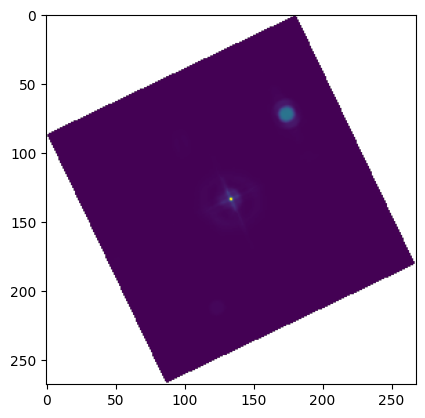

In [78]:
plt.imshow(tata)
plt.show()

In [ ]:
#### lire les anciennes lim de det et les comparer aux nouvelles pour AM

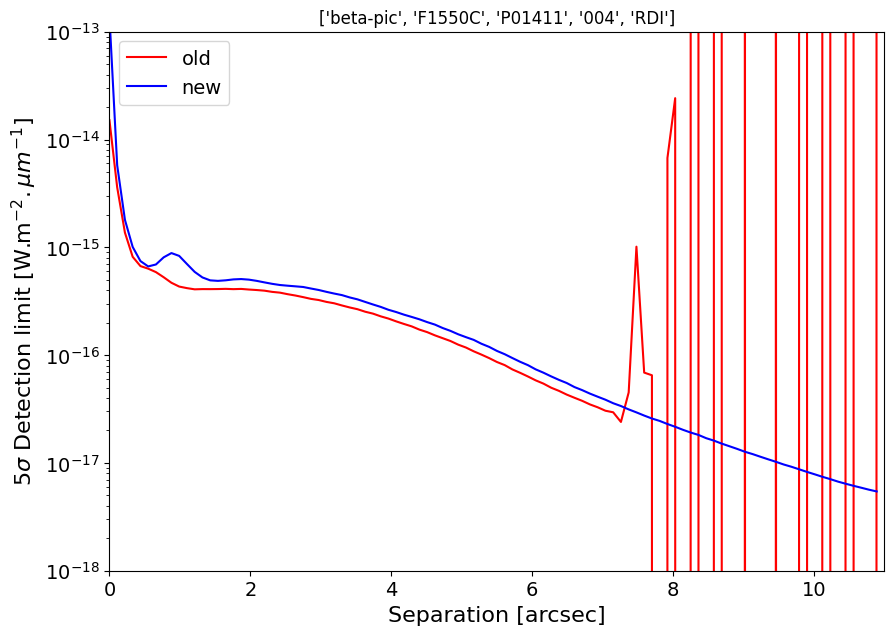

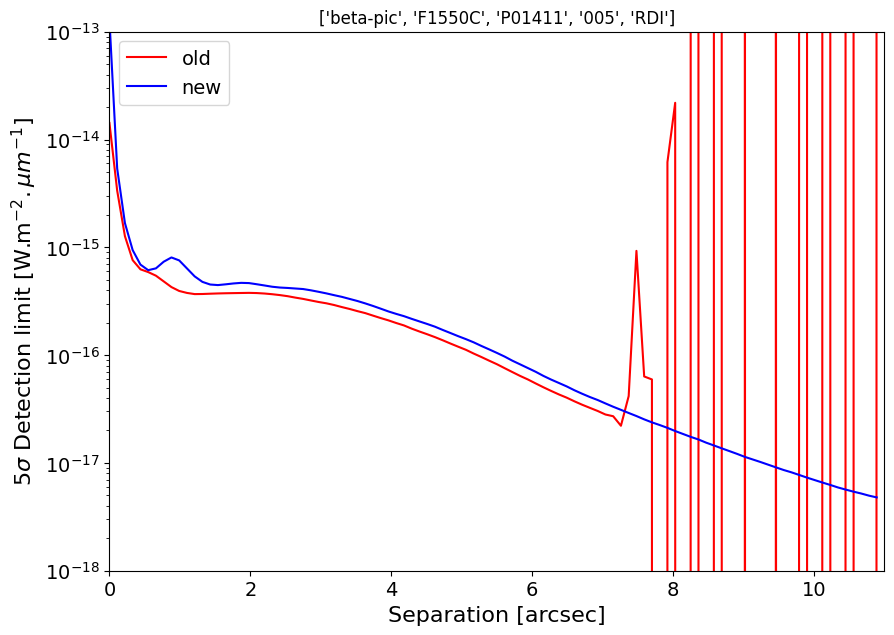

In [59]:
path_data_old = "/home/cperrot/Work/projet/JWST/Target/GO/lim_det/old_lim_paper/"
path_data_new = "/home/cperrot/Work/projet/JWST/Target/GO/lim_det/"
path_save     = "/home/cperrot/Work/projet/JWST/Target/GO/lim_det/old_lim_paper/"

info = ["beta-pic","F1550C","P01411","004","RDI"]
data_old_1 = np.loadtxt(path_data_old+"/lim_det_"+info[0]+"_"+info[1]+"_"+info[2]+"_"+info[3]+"_"+info[4]+".dat")
data_new_1 = np.loadtxt(path_data_new+"/lim_det_wm2_"+info[0]+"_obs"+info[3]+"_"+info[1]+"_45deg.dat")


fig1 = plt.figure(figsize=(10,7))
plt.plot(data_old_1[:,0],data_old_1[:,2],color="red",label="old")
plt.plot(data_new_1[:,0],data_new_1[:,1],color="blue",label="new")
#plt.plot(data_old_1[:,0],np.abs(data_old_1[:,2]-data_new_1[:,1]),color="green",label="diff")
plt.yscale("log")
plt.title(info)
plt.xlim([0,11])
plt.ylim([1e-18,1e-13])
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.legend(fontsize=14)
plt.xlabel('Separation [arcsec]', fontsize=16)
plt.ylabel(r'5$\sigma$ Detection limit [W.m$^{-2}.µm^{-1}$]', fontsize=16)
fig1.savefig(path_save+"det_lim_wm2_old-vs-new_"+info[0]+"_"+info[1]+"_"+info[3]+".pdf",format='pdf',bbox_inches='tight')


info = ["beta-pic","F1550C","P01411","005","RDI"]
data_old_2 = np.loadtxt(path_data_old+"/lim_det_"+info[0]+"_"+info[1]+"_"+info[2]+"_"+info[3]+"_"+info[4]+".dat")
data_new_2 = np.loadtxt(path_data_new+"/lim_det_wm2_"+info[0]+"_obs"+info[3]+"_"+info[1]+"_45deg.dat")



fig1 = plt.figure(figsize=(10,7))
plt.plot(data_old_2[:,0],data_old_2[:,2],color="red",label="old")
plt.plot(data_new_2[:,0],data_new_2[:,1],color="blue",label="new")
#plt.plot(data_old_2[:,0],np.abs(data_old_2[:,2]-data_new_2[:,1]),color="green",label="diff")
plt.yscale("log")
plt.title(info)
plt.xlim([0,11])
plt.ylim([1e-18,1e-13])
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.legend(fontsize=14)
plt.xlabel('Separation [arcsec]', fontsize=16)
plt.ylabel(r'5$\sigma$ Detection limit [W.m$^{-2}.µm^{-1}$]', fontsize=16)
fig1.savefig(path_save+"det_lim_wm2_old-vs-new_"+info[0]+"_"+info[1]+"_"+info[3]+".pdf",format='pdf',bbox_inches='tight')

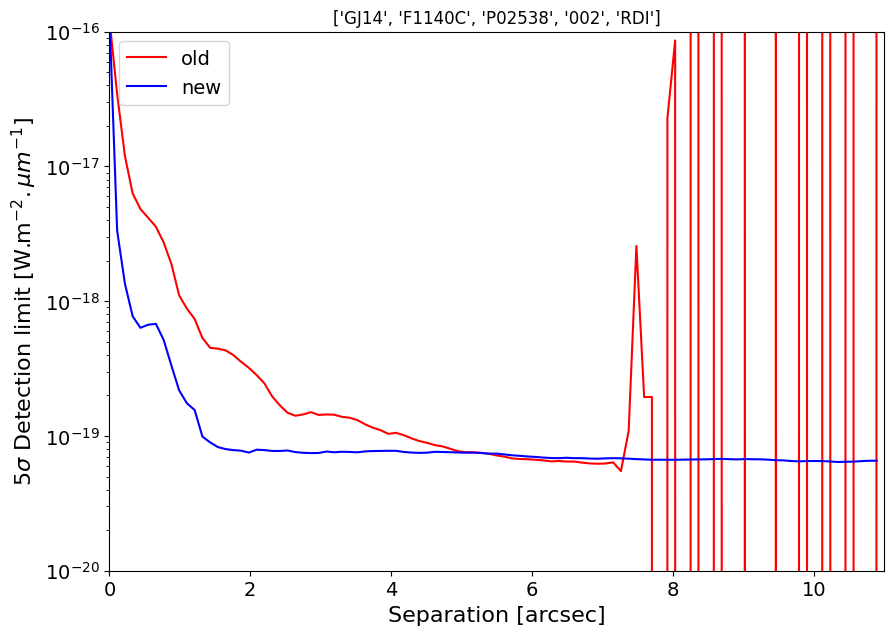

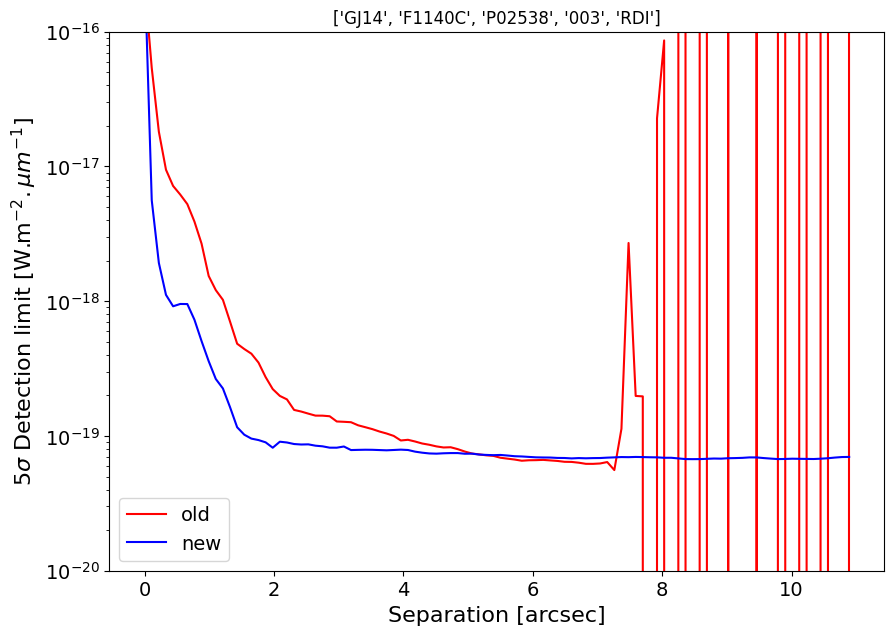

In [60]:
info = ["GJ14","F1140C","P02538","002","RDI"]
data_old_1 = np.loadtxt(path_data_old+"/lim_det_"+info[0]+"_"+info[1]+"_"+info[2]+"_"+info[3]+"_"+info[4]+".dat")
data_new_1 = np.loadtxt(path_data_new+"/lim_det_wm2_"+info[0]+"_obs"+info[3]+"_"+info[1]+"_45deg.dat")


fig1 = plt.figure(figsize=(10,7))
plt.plot(data_old_1[:,0],data_old_1[:,2],color="red",label="old")
plt.plot(data_new_1[:,0],data_new_1[:,1],color="blue",label="new")
#plt.plot(data_old_1[:,0],np.abs(data_old_1[:,2]-data_new_1[:,1]),color="green",label="diff")
plt.yscale("log")
plt.title(info)
plt.xlim([0,11])
plt.ylim([1e-20,1e-16])
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.legend(fontsize=14)
plt.xlabel('Separation [arcsec]', fontsize=16)
plt.ylabel(r'5$\sigma$ Detection limit [W.m$^{-2}.µm^{-1}$]', fontsize=16)
fig1.savefig(path_save+"det_lim_wm2_old-vs-new_"+info[0]+"_"+info[1]+"_"+info[3]+".pdf",format='pdf',bbox_inches='tight')

info = ["GJ14","F1140C","P02538","003","RDI"]
data_old_2 = np.loadtxt(path_data_old+"/lim_det_"+info[0]+"_"+info[1]+"_"+info[2]+"_"+info[3]+"_"+info[4]+".dat")
data_new_2 = np.loadtxt(path_data_new+"/lim_det_wm2_"+info[0]+"_obs"+info[3]+"_"+info[1]+"_45deg.dat")



fig1 = plt.figure(figsize=(10,7))
plt.plot(data_old_2[:,0],data_old_2[:,2],color="red",label="old")
plt.plot(data_new_2[:,0],data_new_2[:,1],color="blue",label="new")
#plt.plot(data_old_2[:,0],np.abs(data_old_2[:,2]-data_new_2[:,1]),color="green",label="diff")
plt.yscale("log")
plt.title(info)
plt.ylim([1e-20,1e-16])
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.legend(fontsize=14)
plt.xlabel('Separation [arcsec]', fontsize=16)
plt.ylabel(r'5$\sigma$ Detection limit [W.m$^{-2}.µm^{-1}$]', fontsize=16)
fig1.savefig(path_save+"det_lim_wm2_old-vs-new_"+info[0]+"_"+info[1]+"_"+info[3]+".pdf",format='pdf',bbox_inches='tight')

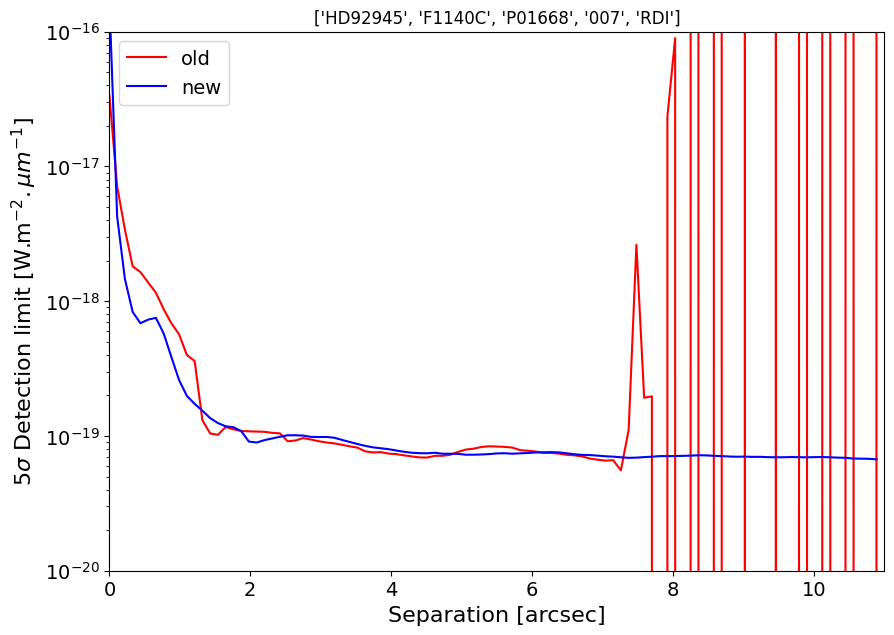

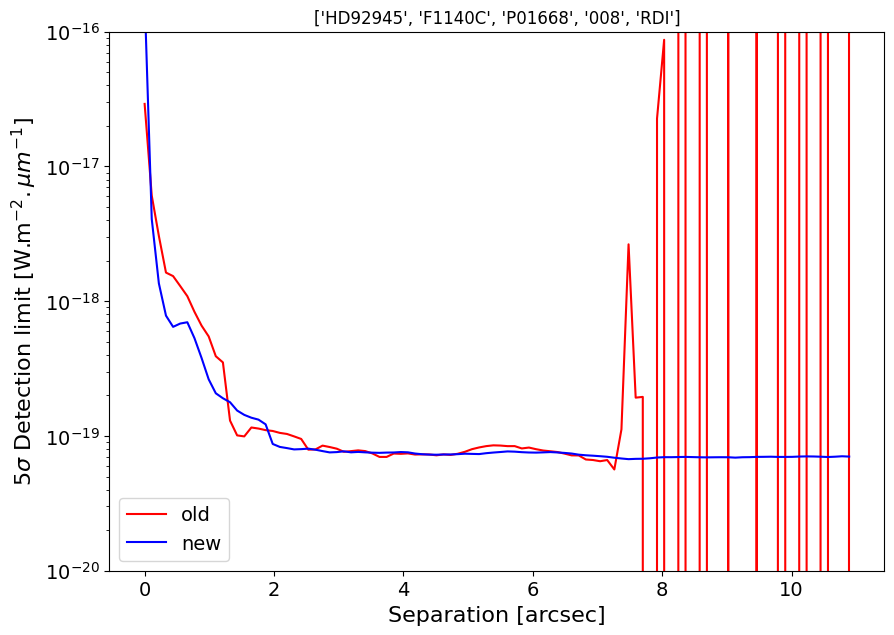

In [61]:
info = ["HD92945","F1140C","P01668","007","RDI"]
data_old_1 = np.loadtxt(path_data_old+"/lim_det_"+info[0]+"_"+info[1]+"_"+info[2]+"_"+info[3]+"_"+info[4]+".dat")
data_new_1 = np.loadtxt(path_data_new+"/lim_det_wm2_"+info[0]+"_obs"+info[3]+"_"+info[1]+"_45deg.dat")

fig1 = plt.figure(figsize=(10,7))
plt.plot(data_old_1[:,0],data_old_1[:,2],color="red",label="old")
plt.plot(data_new_1[:,0],data_new_1[:,1],color="blue",label="new")
#plt.plot(data_old_1[:,0],np.abs(data_old_1[:,2]-data_new_1[:,1]),color="green",label="diff")
plt.yscale("log")
plt.title(info)
plt.xlim([0,11])
plt.ylim([1e-20,1e-16])
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.legend(fontsize=14)
plt.xlabel('Separation [arcsec]', fontsize=16)
plt.ylabel(r'5$\sigma$ Detection limit [W.m$^{-2}.µm^{-1}$]', fontsize=16)
fig1.savefig(path_save+"det_lim_wm2_old-vs-new_"+info[0]+"_"+info[1]+"_"+info[3]+".pdf",format='pdf',bbox_inches='tight')

info = ["HD92945","F1140C","P01668","008","RDI"]
data_old_2 = np.loadtxt(path_data_old+"/lim_det_"+info[0]+"_"+info[1]+"_"+info[2]+"_"+info[3]+"_"+info[4]+".dat")
data_new_2 = np.loadtxt(path_data_new+"/lim_det_wm2_"+info[0]+"_obs"+info[3]+"_"+info[1]+"_45deg.dat")



fig1 = plt.figure(figsize=(10,7))
plt.plot(data_old_2[:,0],data_old_2[:,2],color="red",label="old")
plt.plot(data_new_2[:,0],data_new_2[:,1],color="blue",label="new")
#plt.plot(data_old_2[:,0],np.abs(data_old_2[:,2]-data_new_2[:,1]),color="green",label="diff")
plt.yscale("log")
plt.title(info)
plt.ylim([1e-20,1e-16])
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.legend(fontsize=14)
plt.xlabel('Separation [arcsec]', fontsize=16)
plt.ylabel(r'5$\sigma$ Detection limit [W.m$^{-2}.µm^{-1}$]', fontsize=16)
fig1.savefig(path_save+"det_lim_wm2_old-vs-new_"+info[0]+"_"+info[1]+"_"+info[3]+".pdf",format='pdf',bbox_inches='tight')

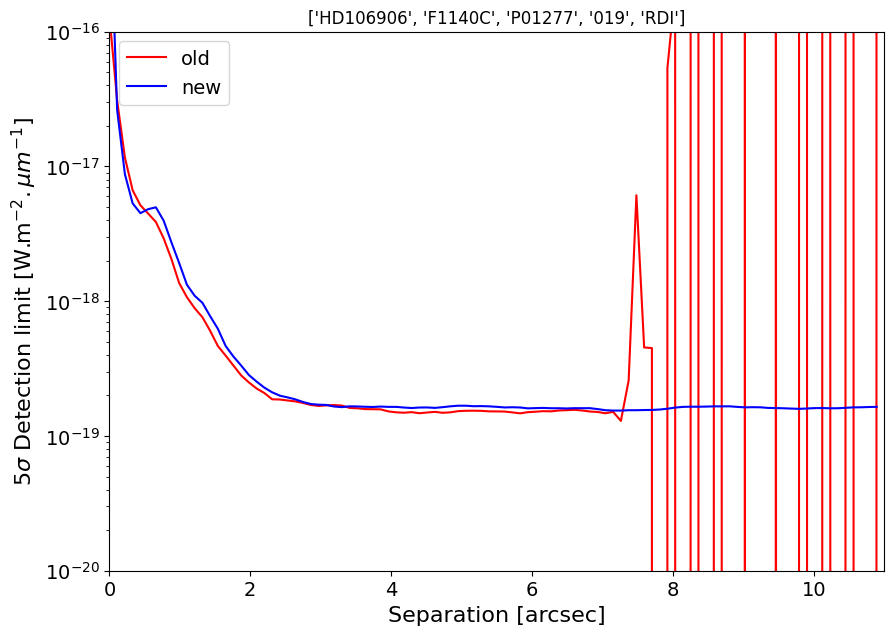

In [62]:
info = ["HD106906","F1140C","P01277","019","RDI"]
data_old_1 = np.loadtxt(path_data_old+"/lim_det_"+info[0]+"_"+info[1]+"_"+info[2]+"_"+info[3]+"_"+info[4]+".dat")
data_new_1 = np.loadtxt(path_data_new+"/lim_det_wm2_"+info[0]+"_obs"+info[3]+"_"+info[1]+"_45deg.dat")


fig1 = plt.figure(figsize=(10,7))
plt.plot(data_old_1[:,0],data_old_1[:,2],color="red",label="old")
plt.plot(data_new_1[:,0],data_new_1[:,1],color="blue",label="new")
#plt.plot(data_old_1[:,0],np.abs(data_old_1[:,2]-data_new_1[:,1]),color="green",label="diff")
plt.yscale("log")
plt.title(info)
plt.xlim([0,11])
plt.ylim([1e-20,1e-16])
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.legend(fontsize=14)
plt.xlabel('Separation [arcsec]', fontsize=16)
plt.ylabel(r'5$\sigma$ Detection limit [W.m$^{-2}.µm^{-1}$]', fontsize=16)
fig1.savefig(path_save+"det_lim_wm2_old-vs-new_"+info[0]+"_"+info[1]+"_"+info[3]+".pdf",format='pdf',bbox_inches='tight')


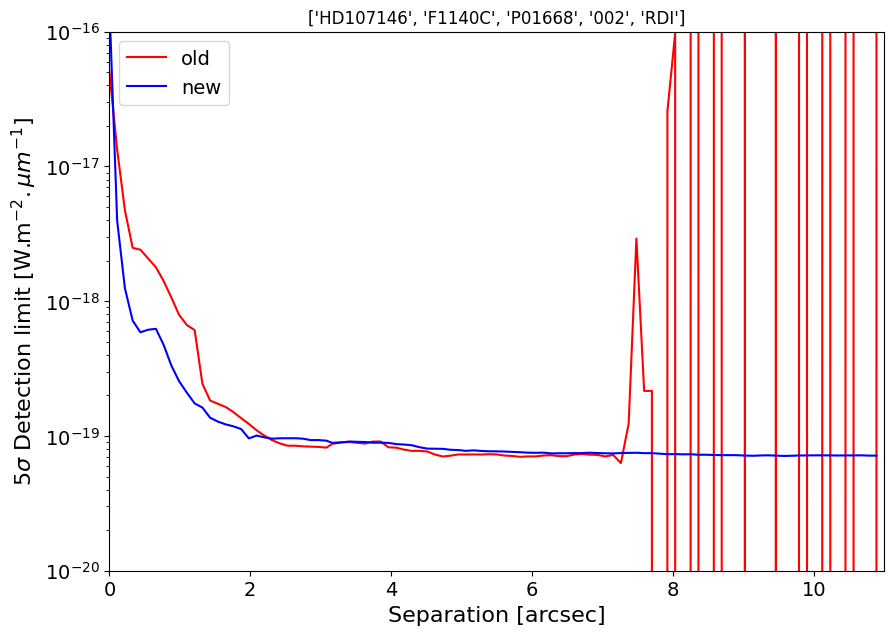

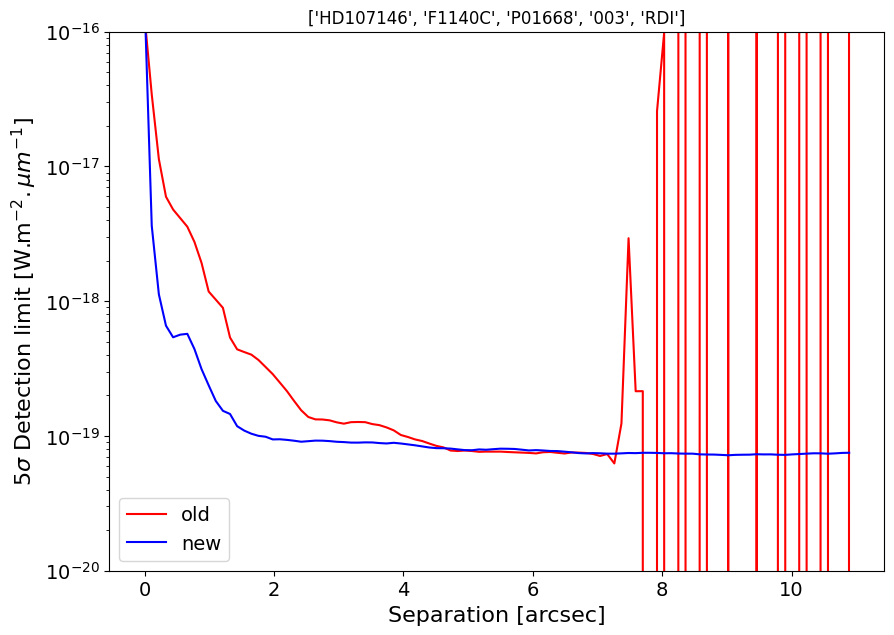

In [63]:
info = ["HD107146","F1140C","P01668","002","RDI"]
data_old_1 = np.loadtxt(path_data_old+"/lim_det_"+info[0]+"_"+info[1]+"_"+info[2]+"_"+info[3]+"_"+info[4]+".dat")
data_new_1 = np.loadtxt(path_data_new+"/lim_det_wm2_"+info[0]+"_obs"+info[3]+"_"+info[1]+"_45deg.dat")

fig1 = plt.figure(figsize=(10,7))
plt.plot(data_old_1[:,0],data_old_1[:,2],color="red",label="old")
plt.plot(data_new_1[:,0],data_new_1[:,1],color="blue",label="new")
#plt.plot(data_old_1[:,0],np.abs(data_old_1[:,2]-data_new_1[:,1]),color="green",label="diff")
plt.yscale("log")
plt.title(info)
plt.xlim([0,11])
plt.ylim([1e-20,1e-16])
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.legend(fontsize=14)
plt.xlabel('Separation [arcsec]', fontsize=16)
plt.ylabel(r'5$\sigma$ Detection limit [W.m$^{-2}.µm^{-1}$]', fontsize=16)
fig1.savefig(path_save+"det_lim_wm2_old-vs-new_"+info[0]+"_"+info[1]+"_"+info[3]+".pdf",format='pdf',bbox_inches='tight')

info = ["HD107146","F1140C","P01668","003","RDI"]
data_old_2 = np.loadtxt(path_data_old+"/lim_det_"+info[0]+"_"+info[1]+"_"+info[2]+"_"+info[3]+"_"+info[4]+".dat")
data_new_2 = np.loadtxt(path_data_new+"/lim_det_wm2_"+info[0]+"_obs"+info[3]+"_"+info[1]+"_45deg.dat")



fig1 = plt.figure(figsize=(10,7))
plt.plot(data_old_2[:,0],data_old_2[:,2],color="red",label="old")
plt.plot(data_new_2[:,0],data_new_2[:,1],color="blue",label="new")
#plt.plot(data_old_2[:,0],np.abs(data_old_2[:,2]-data_new_2[:,1]),color="green",label="diff")
plt.yscale("log")
plt.title(info)
plt.ylim([1e-20,1e-16])
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.legend(fontsize=14)
plt.xlabel('Separation [arcsec]', fontsize=16)
plt.ylabel(r'5$\sigma$ Detection limit [W.m$^{-2}.µm^{-1}$]', fontsize=16)
fig1.savefig(path_save+"det_lim_wm2_old-vs-new_"+info[0]+"_"+info[1]+"_"+info[3]+".pdf",format='pdf',bbox_inches='tight')

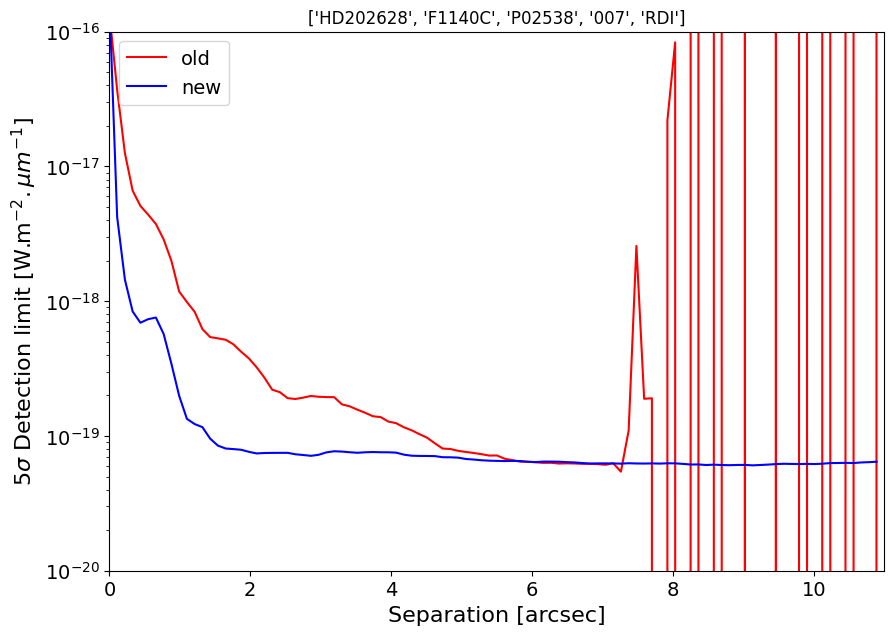

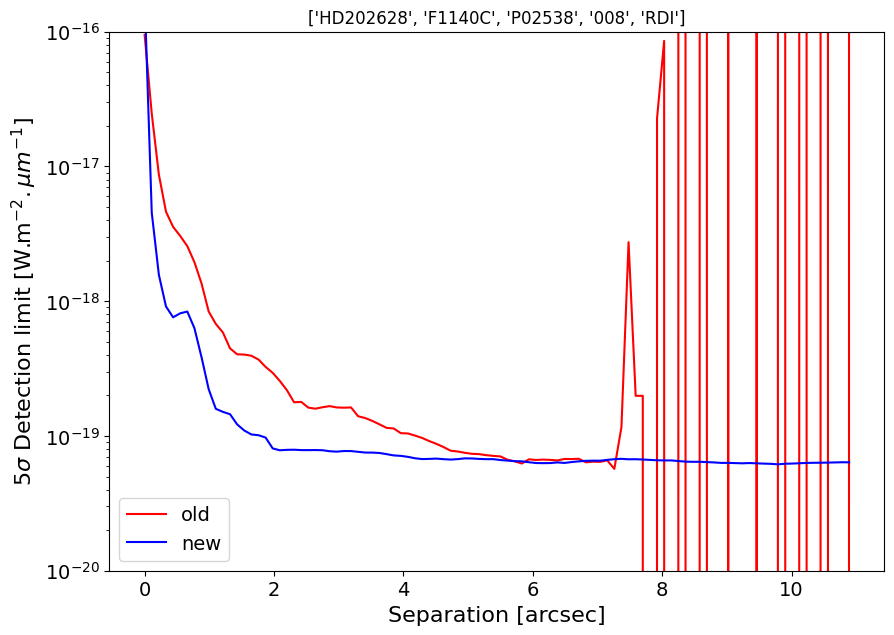

In [64]:
info = ["HD202628","F1140C","P02538","007","RDI"]
data_old_1 = np.loadtxt(path_data_old+"/lim_det_"+info[0]+"_"+info[1]+"_"+info[2]+"_"+info[3]+"_"+info[4]+".dat")
data_new_1 = np.loadtxt(path_data_new+"/lim_det_wm2_"+info[0]+"_obs"+info[3]+"_"+info[1]+"_45deg.dat")

fig1 = plt.figure(figsize=(10,7))
plt.plot(data_old_1[:,0],data_old_1[:,2],color="red",label="old")
plt.plot(data_new_1[:,0],data_new_1[:,1],color="blue",label="new")
#plt.plot(data_old_1[:,0],np.abs(data_old_1[:,2]-data_new_1[:,1]),color="green",label="diff")
plt.yscale("log")
plt.title(info)
plt.xlim([0,11])
plt.ylim([1e-20,1e-16])
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.legend(fontsize=14)
plt.xlabel('Separation [arcsec]', fontsize=16)
plt.ylabel(r'5$\sigma$ Detection limit [W.m$^{-2}.µm^{-1}$]', fontsize=16)
fig1.savefig(path_save+"det_lim_wm2_old-vs-new_"+info[0]+"_"+info[1]+"_"+info[3]+".pdf",format='pdf',bbox_inches='tight')

info = ["HD202628","F1140C","P02538","008","RDI"]
data_old_2 = np.loadtxt(path_data_old+"/lim_det_"+info[0]+"_"+info[1]+"_"+info[2]+"_"+info[3]+"_"+info[4]+".dat")
data_new_2 = np.loadtxt(path_data_new+"/lim_det_wm2_"+info[0]+"_obs"+info[3]+"_"+info[1]+"_45deg.dat")



fig1 = plt.figure(figsize=(10,7))
plt.plot(data_old_2[:,0],data_old_2[:,2],color="red",label="old")
plt.plot(data_new_2[:,0],data_new_2[:,1],color="blue",label="new")
#plt.plot(data_old_2[:,0],np.abs(data_old_2[:,2]-data_new_2[:,1]),color="green",label="diff")
plt.yscale("log")
plt.title(info)
plt.ylim([1e-20,1e-16])
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.legend(fontsize=14)
plt.xlabel('Separation [arcsec]', fontsize=16)
plt.ylabel(r'5$\sigma$ Detection limit [W.m$^{-2}.µm^{-1}$]', fontsize=16)
fig1.savefig(path_save+"det_lim_wm2_old-vs-new_"+info[0]+"_"+info[1]+"_"+info[3]+".pdf",format='pdf',bbox_inches='tight')

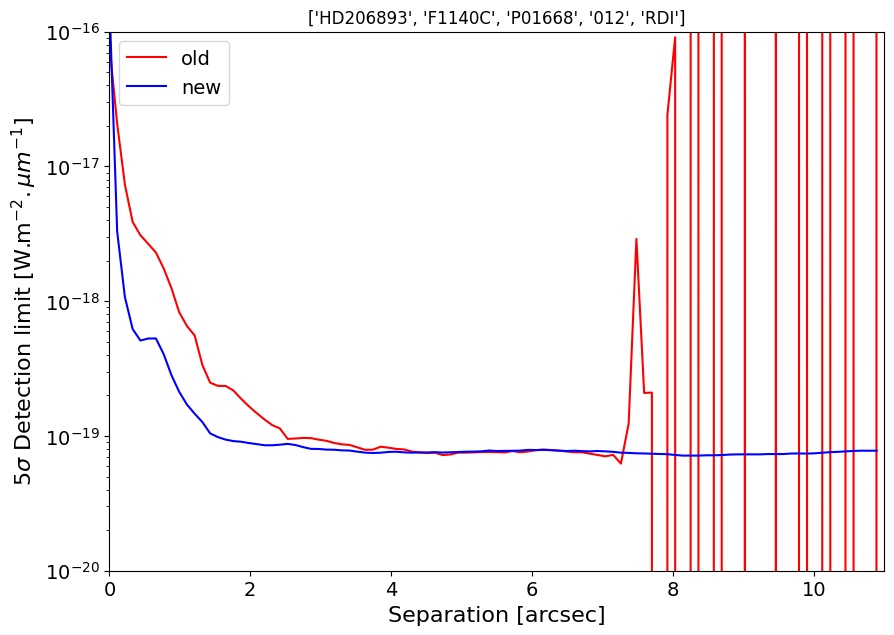

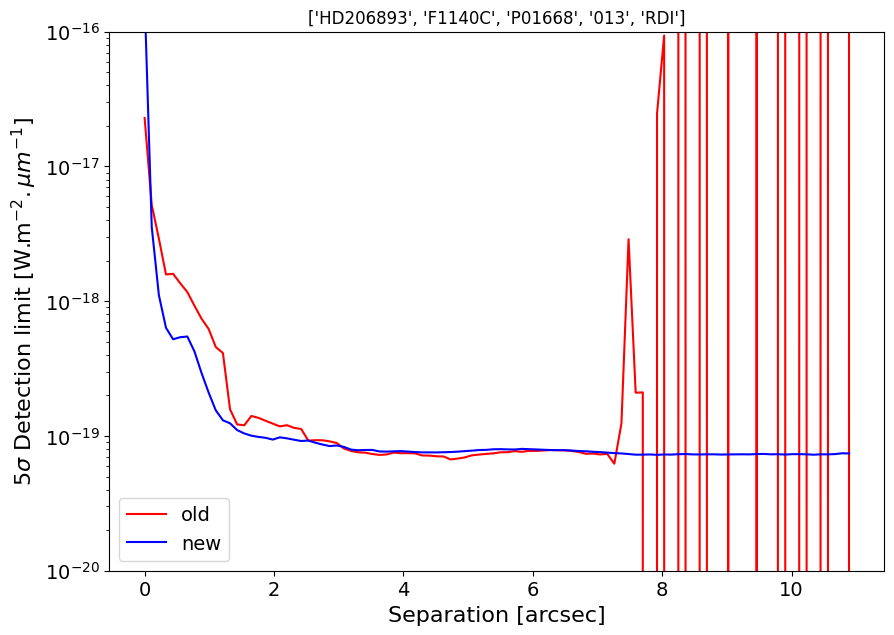

In [ ]:
info = ["HD206893","F1140C","P01668","012","RDI"]
data_old_1 = np.loadtxt(path_data_old+"/lim_det_"+info[0]+"_"+info[1]+"_"+info[2]+"_"+info[3]+"_"+info[4]+".dat")
data_new_1 = np.loadtxt(path_data_new+"/lim_det_wm2_"+info[0]+"_obs"+info[3]+"_"+info[1]+"_45deg.dat")

fig1 = plt.figure(figsize=(10,7))
plt.plot(data_old_1[:,0],data_old_1[:,2],color="red",label="old")
plt.plot(data_new_1[:,0],data_new_1[:,1],color="blue",label="new")
#plt.plot(data_old_1[:,0],np.abs(data_old_1[:,2]-data_new_1[:,1]),color="green",label="diff")
plt.yscale("log")
plt.title(info)
plt.xlim([0,11])
plt.ylim([1e-20,1e-16])
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.legend(fontsize=14)
plt.xlabel('Separation [arcsec]', fontsize=16)
plt.ylabel(r'5$\sigma$ Detection limit [W.m$^{-2}.µm^{-1}$]', fontsize=16)
fig1.savefig(path_save+"det_lim_wm2_old-vs-new_"+info[0]+"_"+info[1]+"_"+info[3]+".pdf",format='pdf',bbox_inches='tight')


info = ["HD206893","F1140C","P01668","013","RDI"]
data_old_2 = np.loadtxt(path_data_old+"/lim_det_"+info[0]+"_"+info[1]+"_"+info[2]+"_"+info[3]+"_"+info[4]+".dat")
data_new_2 = np.loadtxt(path_data_new+"/lim_det_wm2_"+info[0]+"_obs"+info[3]+"_"+info[1]+"_45deg.dat")



fig1 = plt.figure(figsize=(10,7))
plt.plot(data_old_2[:,0],data_old_2[:,2],color="red",label="old")
plt.plot(data_new_2[:,0],data_new_2[:,1],color="blue",label="new")
#plt.plot(data_old_2[:,0],np.abs(data_old_2[:,2]-data_new_2[:,1]),color="green",label="diff")
plt.yscale("log")
plt.title(info)
plt.ylim([1e-20,1e-16])
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.legend(fontsize=14)
plt.xlabel('Separation [arcsec]', fontsize=16)
plt.ylabel(r'5$\sigma$ Detection limit [W.m$^{-2}.µm^{-1}$]', fontsize=16)
fig1.savefig(path_save+"det_lim_wm2_old-vs-new_"+info[0]+"_"+info[1]+"_"+info[3]+".pdf",format='pdf',bbox_inches='tight')

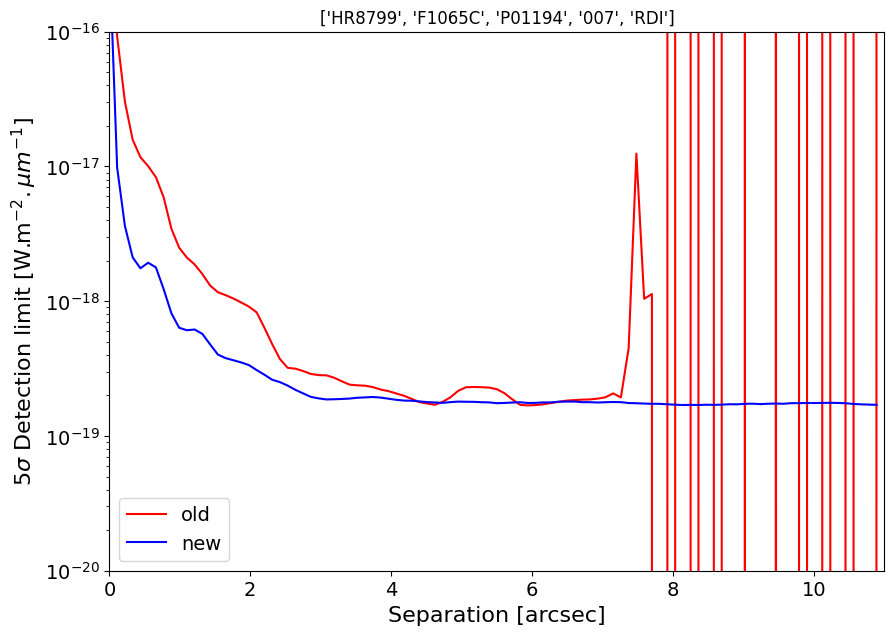

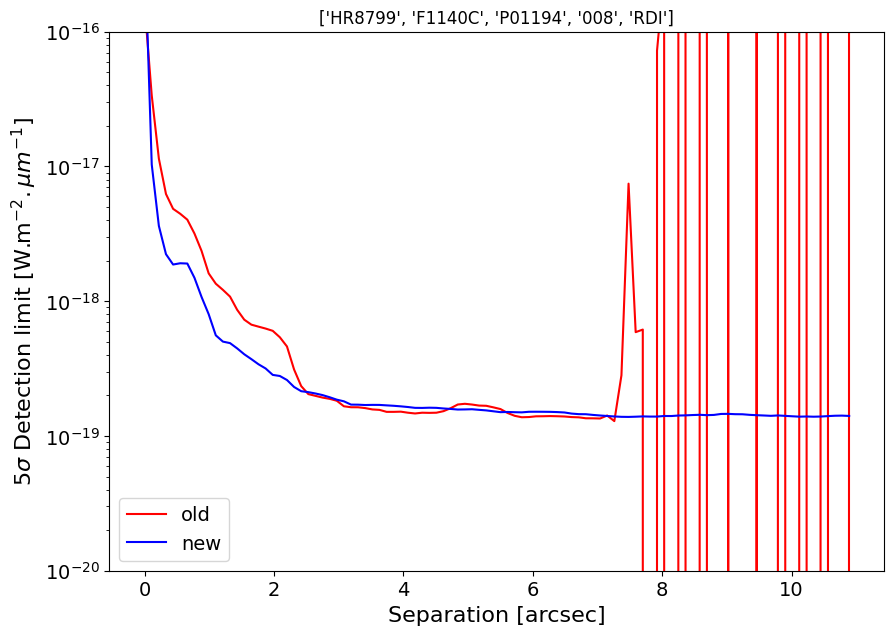

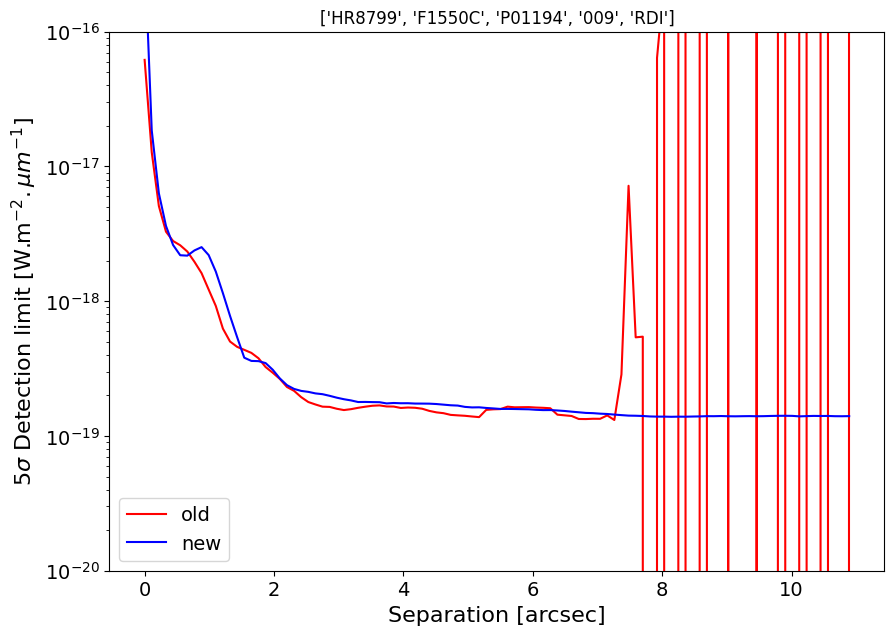

In [66]:
info = ["HR8799","F1065C","P01194","007","RDI"]
data_old_1 = np.loadtxt(path_data_old+"/lim_det_"+info[0]+"_"+info[1]+"_"+info[2]+"_"+info[3]+"_"+info[4]+".dat")
data_new_1 = np.loadtxt(path_data_new+"/lim_det_wm2_"+info[0]+"_obs"+info[3]+"_"+info[1]+"_45deg.dat")

fig1 = plt.figure(figsize=(10,7))
plt.plot(data_old_1[:,0],data_old_1[:,2],color="red",label="old")
plt.plot(data_new_1[:,0],data_new_1[:,1],color="blue",label="new")
#plt.plot(data_old_1[:,0],np.abs(data_old_1[:,2]-data_new_1[:,1]),color="green",label="diff")
plt.yscale("log")
plt.title(info)
plt.xlim([0,11])
plt.ylim([1e-20,1e-16])
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.legend(fontsize=14)
plt.xlabel('Separation [arcsec]', fontsize=16)
plt.ylabel(r'5$\sigma$ Detection limit [W.m$^{-2}.µm^{-1}$]', fontsize=16)
fig1.savefig(path_save+"det_lim_wm2_old-vs-new_"+info[0]+"_"+info[1]+"_"+info[3]+".pdf",format='pdf',bbox_inches='tight')


info = ["HR8799","F1140C","P01194","008","RDI"]
data_old_2 = np.loadtxt(path_data_old+"/lim_det_"+info[0]+"_"+info[1]+"_"+info[2]+"_"+info[3]+"_"+info[4]+".dat")
data_new_2 = np.loadtxt(path_data_new+"/lim_det_wm2_"+info[0]+"_obs"+info[3]+"_"+info[1]+"_45deg.dat")


fig1 = plt.figure(figsize=(10,7))
plt.plot(data_old_2[:,0],data_old_2[:,2],color="red",label="old")
plt.plot(data_new_2[:,0],data_new_2[:,1],color="blue",label="new")
#plt.plot(data_old_2[:,0],np.abs(data_old_2[:,2]-data_new_2[:,1]),color="green",label="diff")
plt.yscale("log")
plt.title(info)
plt.ylim([1e-20,1e-16])
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.legend(fontsize=14)
plt.xlabel('Separation [arcsec]', fontsize=16)
plt.ylabel(r'5$\sigma$ Detection limit [W.m$^{-2}.µm^{-1}$]', fontsize=16)
fig1.savefig(path_save+"det_lim_wm2_old-vs-new_"+info[0]+"_"+info[1]+"_"+info[3]+".pdf",format='pdf',bbox_inches='tight')


info = ["HR8799","F1550C","P01194","009","RDI"]
data_old_3 = np.loadtxt(path_data_old+"/lim_det_"+info[0]+"_"+info[1]+"_"+info[2]+"_"+info[3]+"_"+info[4]+".dat")
data_new_3 = np.loadtxt(path_data_new+"/lim_det_wm2_"+info[0]+"_obs"+info[3]+"_"+info[1]+"_45deg.dat")

fig1 = plt.figure(figsize=(10,7))
plt.plot(data_old_3[:,0],data_old_3[:,2],color="red",label="old")
plt.plot(data_new_3[:,0],data_new_3[:,1],color="blue",label="new")
#plt.plot(data_old_2[:,0],np.abs(data_old_2[:,2]-data_new_2[:,1]),color="green",label="diff")
plt.yscale("log")
plt.title(info)
plt.ylim([1e-20,1e-16])
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.legend(fontsize=14)
plt.xlabel('Separation [arcsec]', fontsize=16)
plt.ylabel(r'5$\sigma$ Detection limit [W.m$^{-2}.µm^{-1}$]', fontsize=16)
fig1.savefig(path_save+"det_lim_wm2_old-vs-new_"+info[0]+"_"+info[1]+"_"+info[3]+".pdf",format='pdf',bbox_inches='tight')

In [ ]:
'''
def quick_reduction_miri(name_star, filt, p_id, obs_sci, obs_sci_b, obs_ref, obs_ref_b, path_data, path_bkg, path_save):
    name    = name_star
    fil     = "F"+str(filt)+"C"
    pid     = "{:05d}".format(p_id)
    obssci  = "{:03d}".format(obs_sci)
    obsscib = "{:03d}".format(obs_sci_b)
    obsref  = "{:03d}".format(obs_ref)
    obsrefb = "{:03d}".format(obs_ref_b)
    
    sci_fi     = glob.glob(path_data+fil+"/P"+pid+"_"+obssci+"*_dither1_cal.fits")
    ref_fi     = glob.glob(path_data+fil+"/P"+pid+"_"+obsref+"*_dither?_cal.fits")
    sci_bkg_fi = glob.glob(path_bkg+fil+"/P"+pid+"_"+obsscib+"*_background_dither?_cal.fits")
    ref_bkg_fi = glob.glob(path_bkg+fil+"/P"+pid+"_"+obsrefb+"*_background_dither?_cal.fits")
    
    sci_fi.sort()
    ref_fi.sort()
    sci_bkg_fi.sort()
    ref_bkg_fi.sort()
    
    sci = fits.open(sci_fi[0])[0].data
    ref =[]
    for i in ref_fi: ref.append(fits.open(i)[0].data)
    sci_bkg = np.minimum(fits.open(sci_bkg_fi[0])[0].data, fits.open(sci_bkg_fi[1])[0].data)
    ref_bkg = np.minimum(fits.open(ref_bkg_fi[0])[0].data, fits.open(ref_bkg_fi[1])[0].data)
    
    sci_c = sci - sci_bkg     #science - background
    ref_c = ref - ref_bkg     #reference - background
    
    PCA = imp.sub_PCA(sci_c, ref_c, [100,100], 2, dim=100, plot=False)
    
    # flux scaling for RDI
    f_scale = imp.flux_scaling_ta("/home/cperrot/Work/raw/JWST/Target/MAST/CAL/P"+pid+"/obs"+obssci+'/TA', "/home/cperrot/Work/raw/JWST/Target/MAST/CAL/P"+pid+"/obs"+obsref+'/TA', "cal", filt*10e-8)
    print("f_scale with TA : ",f_scale)
    RDI = imp.RDI_classic(sci_c, ref_c, f_scale=f_scale)

    
    imp.save_fits(PCA, path_save+name+"_"+fil+"_P"+pid+"_"+obssci+"_PCA.fits")
    imp.save_fits(RDI, path_save+name+"_"+fil+"_P"+pid+"_"+obssci+"_RDI.fits")
'''

In [ ]:
path_d = "/home/cperrot/Work/projet/JWST/Target/backgrounds/sci/"
path_b = "/home/cperrot/Work/projet/JWST/Target/backgrounds/obs/"
path_s = "/home/cperrot/Work/projet/JWST/Target/GO/lim_det/"

quick_reduction_miri("HR8799", 1550, 1194, 9, 11, 16, 18, path_d, path_b, path_s)
quick_reduction_miri("HR8799", 1140, 1194, 8, 12, 15, 19, path_d, path_b, path_s)
quick_reduction_miri("HR8799", 1065, 1194, 7, 13, 14, 20, path_d, path_b, path_s)

#1 bkg a traiter séparément
#quick_reduction_miri("beta-pic", 1065, 1241, 28, 26, 29, 31, path_d, path_b, path_s) 
#quick_reduction_miri("beta-pic", 1140, 1241, 27, 25, 30, 32, path_d, path_b, path_s)
quick_reduction_miri("beta-pic", 1550, 1411, 4, 1, 8, 9, path_d, path_b, path_s)
quick_reduction_miri("beta-pic", 1550, 1411, 5, 1, 8, 9, path_d, path_b, path_s)
    
#HD106906 - utiliser une autre ref
#quick_reduction_miri("HD106906", 1550, 1277, 20, 21, , , path_d, path_b, path_s)
quick_reduction_miri("HD106906", 1140, 1277, 19, 22, 8, 11, path_d, path_b, path_s)

quick_reduction_miri("HD107146", 1140, 1668, 2, 1, 4, 5, path_d, path_b, path_s)
quick_reduction_miri("HD107146", 1140, 1668, 3, 1, 4, 5, path_d, path_b, path_s)

quick_reduction_miri("HD92945", 1140, 1668, 7, 6, 9, 10, path_d, path_b, path_s)
quick_reduction_miri("HD92945", 1140, 1668, 8, 6, 9, 10, path_d, path_b, path_s)
 
quick_reduction_miri("HD206893", 1140, 1668, 12, 11, 14, 15, path_d, path_b, path_s)
quick_reduction_miri("HD206893", 1140, 1668, 13, 11, 14, 15, path_d, path_b, path_s) 

quick_reduction_miri("HD202628", 1140, 2538, 7, 6, 9, 10, path_d, path_b, path_s)
quick_reduction_miri("HD202628", 1140, 2538, 8, 6, 9, 10, path_d, path_b, path_s)

quick_reduction_miri("GJ14", 1140, 2538, 2, 1, 4, 5, path_d, path_b, path_s)
quick_reduction_miri("GJ14", 1140, 2538, 3, 1, 4, 5, path_d, path_b, path_s)

Loading of 2 cubes.
Number of dimension : 2
Initial images size (px) : 288 / 224
New images size (px)     : 200 / 200
sigma model PSF:  18.98860522347253
152 156
Roll - TA 1
Result : A = 16917.5 / x0 = 155.97 / y0 = 151.65 / width_x = -1.58 / width_y = -1.55
Stddev : A = 26.4 / x0 = 0.0 / y0 = 0.0 / width_x = 0.0 / width_y = 0.0
112 112
Roll - TA 2
Result : A = 17043.4 / x0 = 112.44 / y0 = 112.56 / width_x = 1.58 / width_y = 1.54
Stddev : A = 25.1 / x0 = 0.0 / y0 = 0.0 / width_x = 0.0 / width_y = 0.0
Loading of 2 cubes.
Number of dimension : 2
Initial images size (px) : 288 / 224
New images size (px)     : 200 / 200
153 156
Ref - TA 1
Result : A = 17844.5 / x0 = 155.74 / y0 = 152.82 / width_x = 1.56 / width_y = -1.52
Stddev : A = 23.8 / x0 = 0.0 / y0 = 0.0 / width_x = 0.0 / width_y = 0.0
112 112
Ref - TA 2
Result : A = 17924.3 / x0 = 112.56 / y0 = 112.56 / width_x = 1.55 / width_y = 1.52
Stddev : A = 25.2 / x0 = 0.0 / y0 = 0.0 / width_x = 0.0 / width_y = 0.0
f_scale with TA :  0.976926

Roll - TA 2
Result : A = 21658.1 / x0 = 116.61 / y0 = 114.58 / width_x = 1.36 / width_y = 1.43
Stddev : A = 53.1 / x0 = 0.0 / y0 = 0.0 / width_x = 0.0 / width_y = 0.0
Loading of 2 cubes.
Number of dimension : 2
Initial images size (px) : 288 / 224
New images size (px)     : 200 / 200
157 156
Ref - TA 1
Result : A = 984002.6 / x0 = 155.95 / y0 = 157.11 / width_x = 1.41 / width_y = 1.49
Stddev : A = 2577.7 / x0 = 0.0 / y0 = 0.0 / width_x = 0.0 / width_y = 0.0
115 117
Ref - TA 2
Result : A = 984228.7 / x0 = 116.62 / y0 = 114.58 / width_x = 1.4 / width_y = 1.48
Stddev : A = 2526.4 / x0 = 0.0 / y0 = 0.0 / width_x = 0.0 / width_y = 0.0
f_scale with TA :  0.02075751327229691
Loading of 2 cubes.
Number of dimension : 2
Initial images size (px) : 288 / 224
New images size (px)     : 200 / 200
sigma model PSF:  13.965812874037859
155 156
Roll - TA 1
Result : A = 21494.1 / x0 = 156.07 / y0 = 155.41 / width_x = 1.38 / width_y = 1.44
Stddev : A = 53.8 / x0 = 0.0 / y0 = 0.0 / width_x = 0.0 / width_y

In [ ]:
def quick_lim_det_miri(name_star, filt, p_id, obs_sci, obs_sci_b, obs_ref, obs_ref_b, mask_obj, path_data, path_bkg, path_save):
    pixscale = 0.11
    V3i      = 4.83544897
    lam      = filt*1e-8
    name    = name_star
    fil     = "F"+str(filt)+"C"
    pid     = "{:05d}".format(p_id)
    obssci  = "{:03d}".format(obs_sci)
    image = fits.open(path_save+name+"_"+fil+"_P"+pid+"_"+obssci+"_RDI.fits")[0].data 
    ydim  = np.shape(image)[-2]
    xdim  = np.shape(image)[-1]
    scale = [(xdim/2.)*pixscale,-1*(xdim/2.)*pixscale,-1*(ydim/2.)*pixscale,(ydim/2.)*pixscale]

    x0 = xdim//2
    y0 = ydim//2


    # transmission
    path_transmission = '/home/cperrot/Work/projet/JWST/Target/Calib/transmission/'
    transmi_sum = fits.open(path_transmission+'transmi_sum.fits')[0].data
    transmi_max = fits.open(path_transmission+'transmi_max.fits')[0].data


    ### Transmission à 45° (optimale)

    t_sum_45 = transmi_sum.copy()
    t_sum_45[np.where(np.isnan(t_sum_45))] = 0
    t_sum_45 = ndimage.rotate(t_sum_45, 45.-V3i, reshape=False)
    t_sum_45 = t_sum_45[xdim//2,:]
    t_sum_45 = (t_sum_45[xdim//2:]+t_sum_45[0:xdim//2][::-1])/2.

    t_max_45 = transmi_max.copy()
    t_max_45[np.where(np.isnan(t_max_45))] = 0
    t_max_45 = ndimage.rotate(t_max_45, 45.-V3i, reshape=False)
    t_max_45 = t_max_45[xdim//2,:]
    t_max_45 = (t_max_45[xdim//2:]+t_max_45[0:xdim//2][::-1])/2.


    ### Transmission à 15° (pas optimale)
    t_sum_15 = transmi_sum.copy()
    t_sum_15[np.where(np.isnan(t_sum_15))] = 0
    t_sum_15 = ndimage.rotate(t_sum_15, 15.-V3i, reshape=False)
    t_sum_15 = t_sum_15[xdim//2,:]
    t_sum_15 = (t_sum_15[xdim//2:]+t_sum_15[0:xdim//2][::-1])/2.

    t_max_15 = transmi_max.copy()
    t_max_15[np.where(np.isnan(t_max_15))] = 0
    t_max_15 = ndimage.rotate(t_max_15, 15.-V3i, reshape=False)
    t_max_15 = t_max_15[xdim//2,:]
    t_max_15 = (t_max_15[xdim//2:]+t_max_15[0:xdim//2][::-1])/2.
    
    image[np.where(mask_obj == 0)] = math.nan



    dr = 1.5*lam/8.5*180.*3600./np.pi/pixscale #pour faire une zone de 1,5*2 = 3 L/D de diametre
    Y, X = np.ogrid[:ydim, :xdim]
    mask_pla = np.sqrt((X - x0+0.5)**2 + (Y-y0+0.5)**2)

    ### Std dev azimutale dans un anneau de 3 L/D de largeur
    std     = np.ndarray(xdim//2)
    std_map = np.ndarray([xdim,xdim])*0.
    for i in range(0,xdim//2):
        mask_sel          = (mask_pla >= i-dr) * (mask_pla < i+dr)
        std[i]            = np.nanstd(image[mask_sel])  ### radial pour roll 1
        std_map[mask_sel] = std[i]                      ### MAP pour roll 1

    ### Calcul pour passer de 1 Sr de surface a 1 pixel de surface
    # 1 pixel = pixscale**2 in arcsec
    # 1 radian = 3600*180/pi arcsec
    # 1 sr = radian**2
    # 1 pixel in sr = (pixscale/(3600*180/np.pi))**2
    #print("1 pixel in sr = ",(pixscale/(3600*180/np.pi))**2)
    pixtosr = (pixscale/(3600*180/np.pi))**2 # y avait un facteur 6^2 et je sais pas pourquoi. Erreur ?
    mjytoujy = 1e12                          #Mjy to µjy
    nbpixel = np.pi*dr**2                    #nombre de pixel dans la zone de photométrie de "dr" l/D de rayon 
    coef=pixtosr*mjytoujy*np.sqrt(nbpixel)*2.25745 # 2,257784785 facteur de correction d'ouverture obtenu avec STPSF : flux in 1.5L/D : 0.25375 ; flux in the image : 0.57283 : 0.57283/0.25375 = 2.25745


    ### passage de µJy a W/m2/µm (les flux sont en MJy/sr mais le facteur de conversion est linéaire et donc peut être fait plus tard)
    std_wm   = flux_uJy_to_Wm(lam*1e6,std)

    lim_det_5sig_t15_wm = np.ndarray(xdim//2)
    lim_det_5sig_t45_wm = np.ndarray(xdim//2)

    file = open(path_save+"lim_det_"+name+"_"+fil+"_P"+pid+"_"+obssci+"_RDI.dat","w")
    for i in range(0,xdim//2):
        #print("{:4.3f}".format((i+0.5)*0.11),"{:4.3f}".format(coef*std_m2[i]),"{:.3e}".format(coef*std_m2_wm[i]))
        lim_det_5sig_t15_wm[i] = 5*coef*std_wm[i]/t_sum_15[i]
        lim_det_5sig_t45_wm[i] = 5*coef*std_wm[i]/t_sum_45[i]
        file.write("{:4.3f}".format(i*0.11)+" {:.3e}".format(lim_det_5sig_t15_wm[i])+" {:.3e}".format(lim_det_5sig_t45_wm[i])+"\n")
    file.close()

    print(name,pid,fil)
    plt.figure(figsize=(8,8))
    plt.imshow(image,origin='lower',cmap='inferno',interpolation='none',vmin=-1,vmax=2,extent=scale) #0.8*np.max(image)
    plt.show()
    
    plt.figure(figsize=(10,6))
    plt.plot(np.arange(0,xdim//2)*0.11, lim_det_5sig_t15_wm)
    plt.yscale('log')
    plt.xlim([0,5.5])
    plt.ylim([1e-20,1e-13])
    plt.show()


HR8799 01194 F1550C


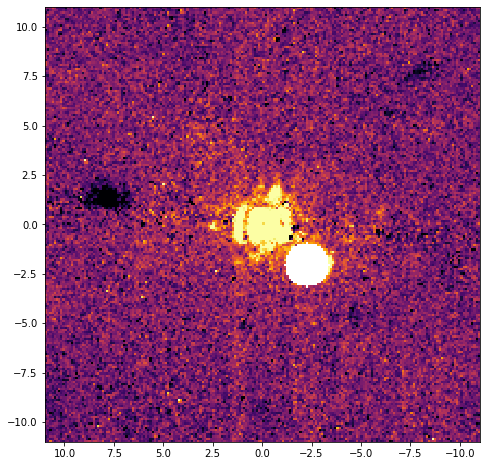

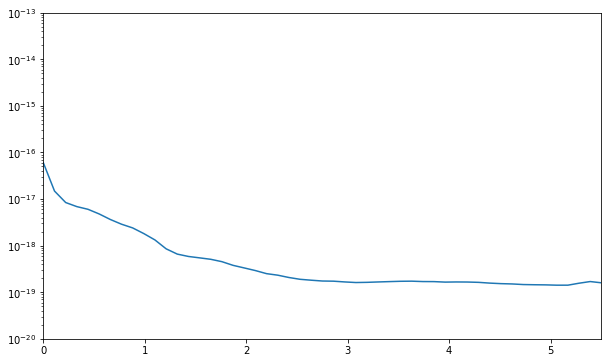

HR8799 01194 F1140C


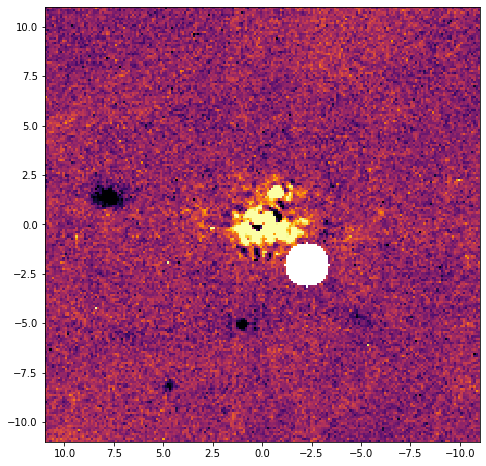

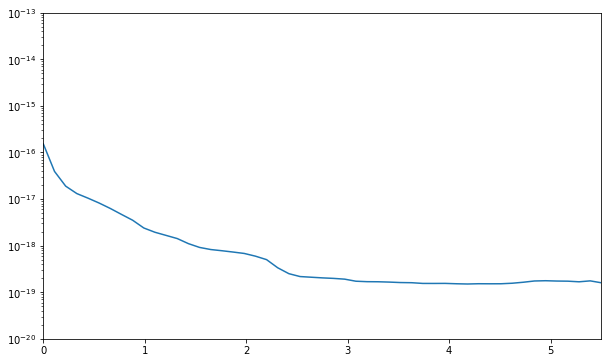

HR8799 01194 F1065C


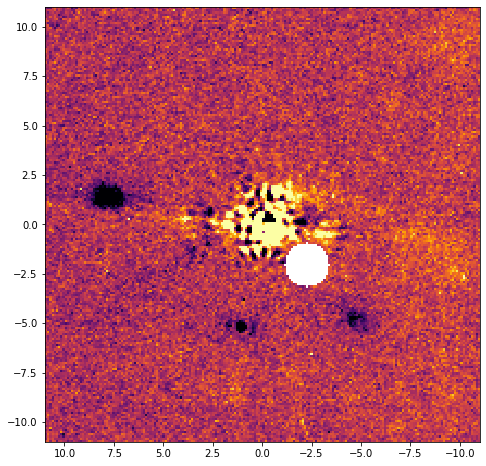

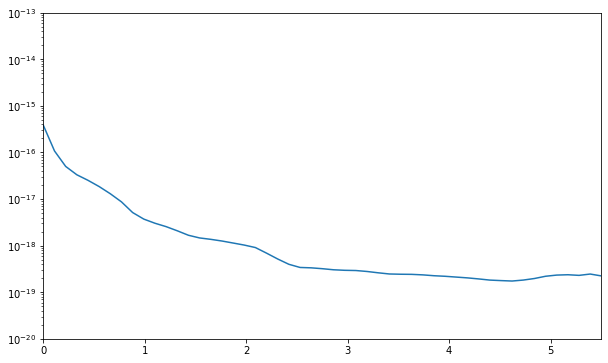

beta-pic 01411 F1550C


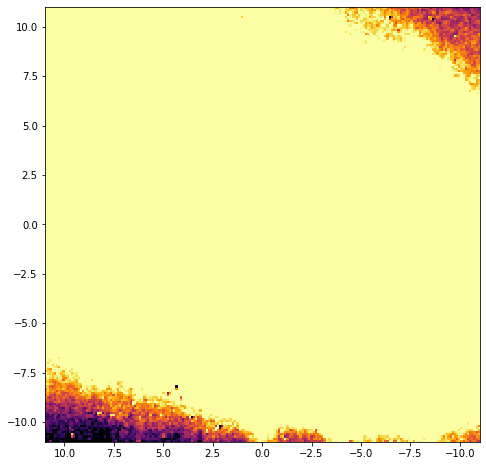

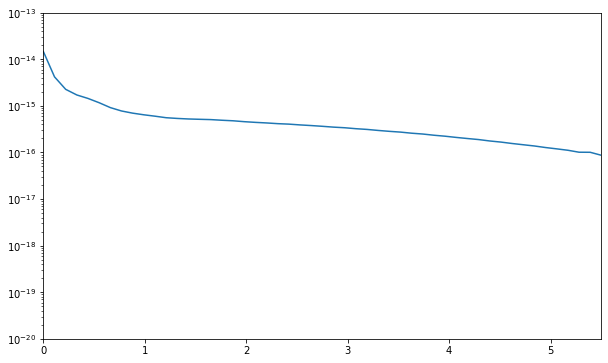

beta-pic 01411 F1550C


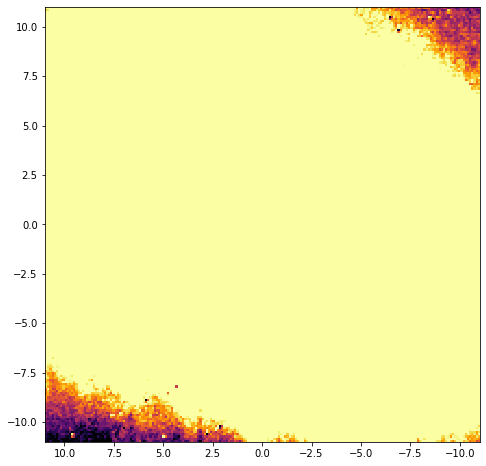

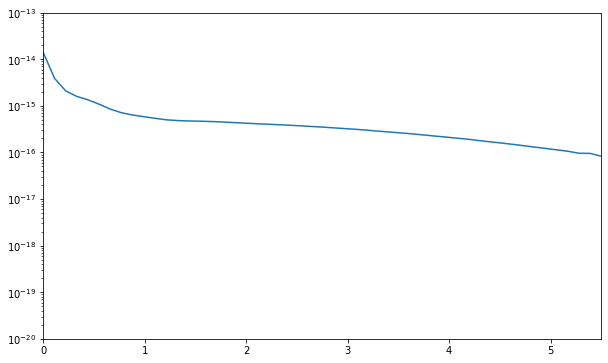

HD106906 01277 F1140C


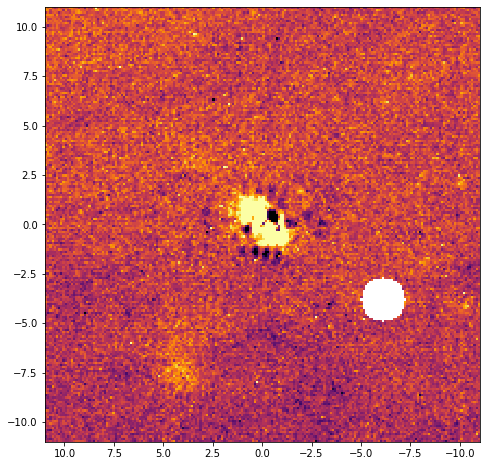

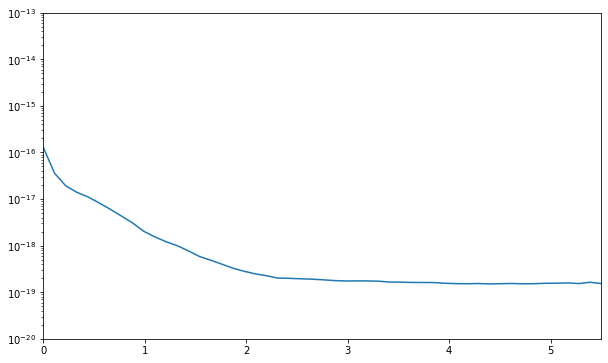

HD107146 01668 F1140C


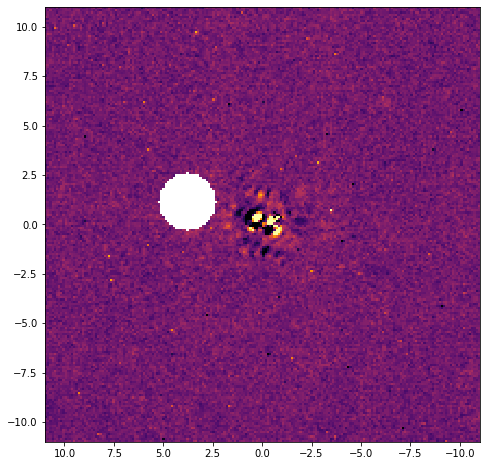

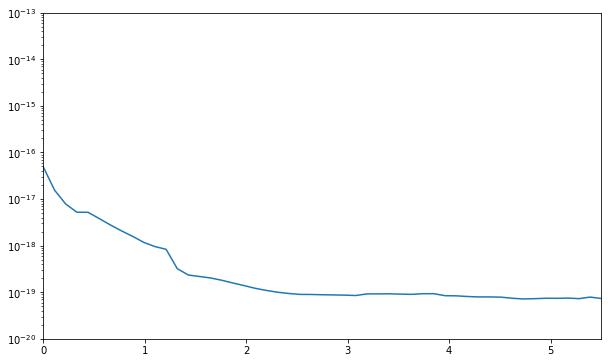

HD107146 01668 F1140C


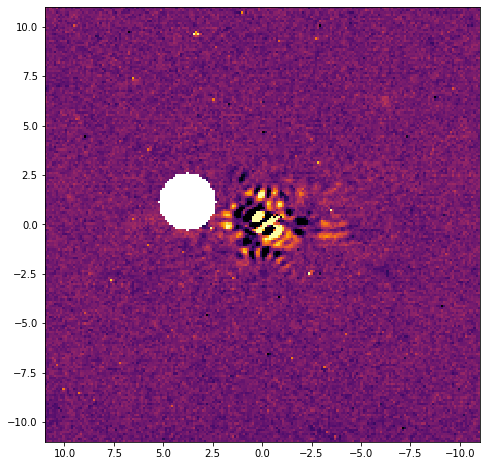

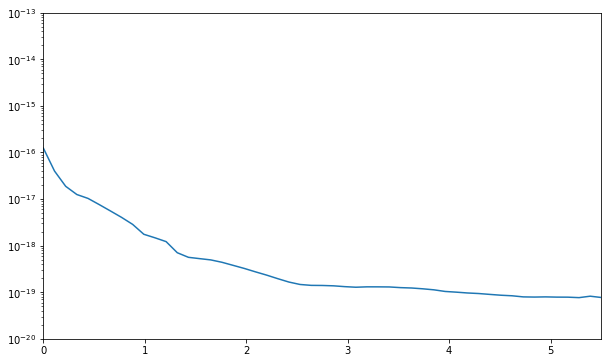

HD92945 01668 F1140C


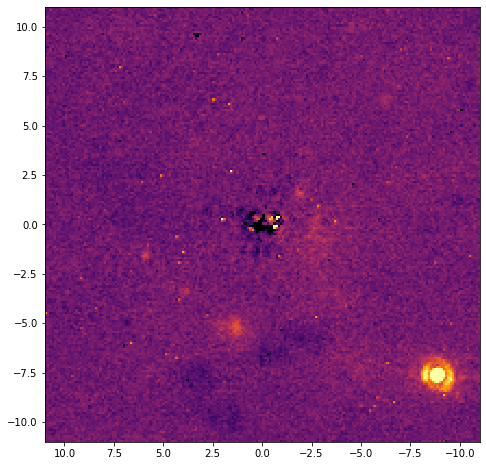

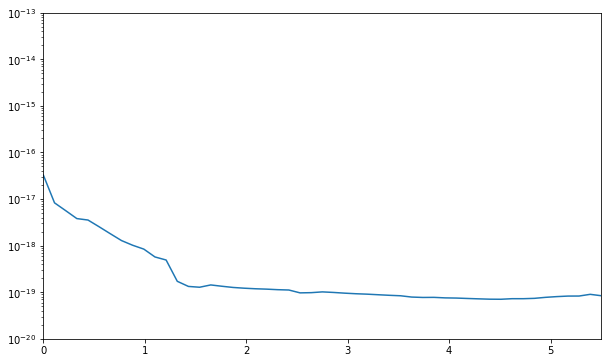

HD92945 01668 F1140C


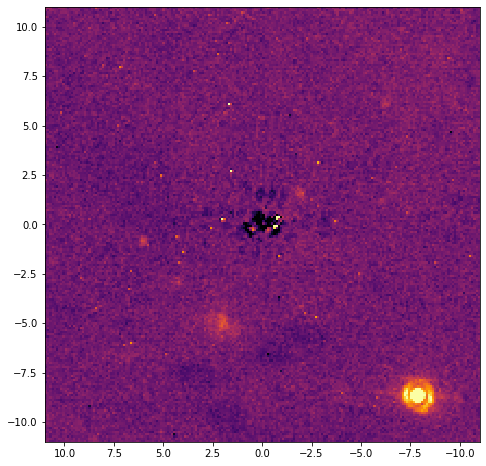

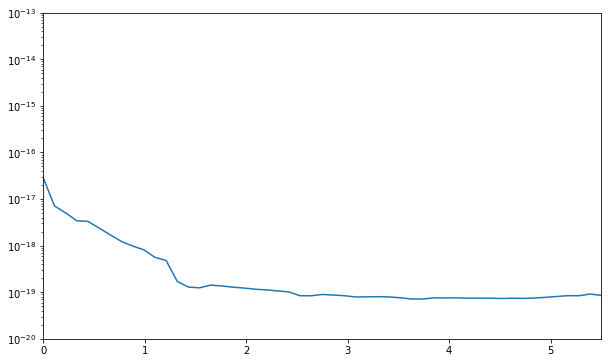

HD206893 01668 F1140C


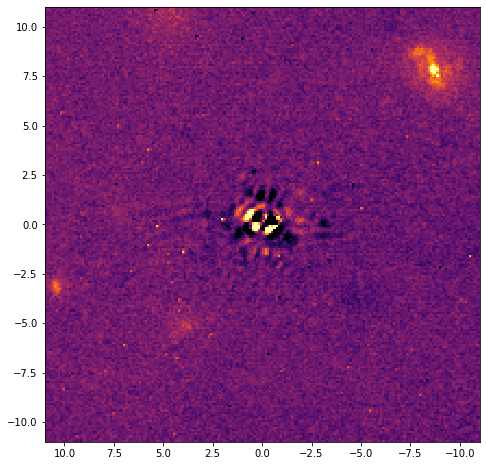

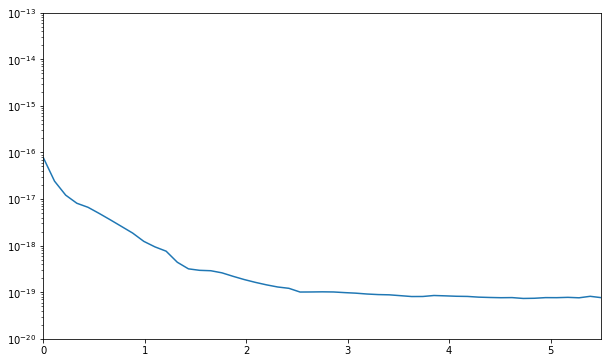

HD206893 01668 F1140C


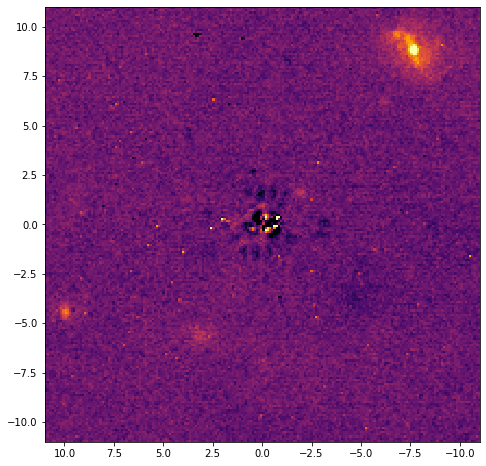

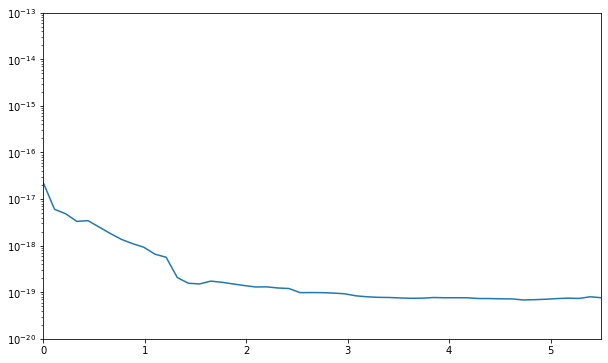

HD202628 02538 F1140C


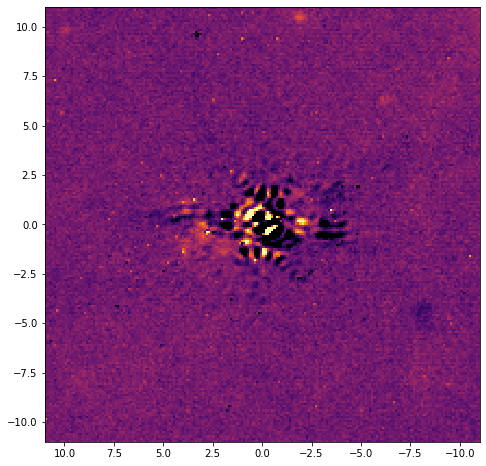

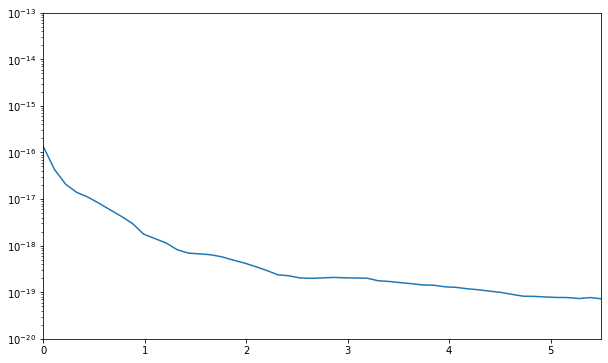

HD202628 02538 F1140C


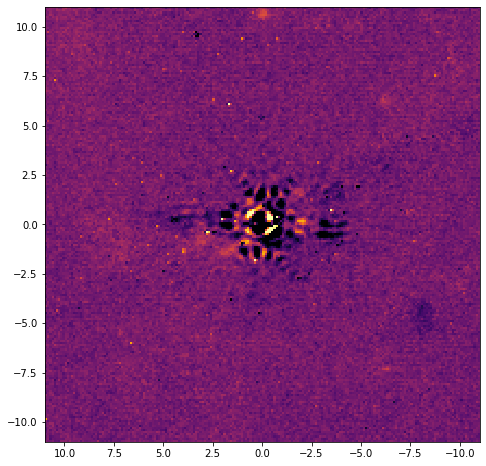

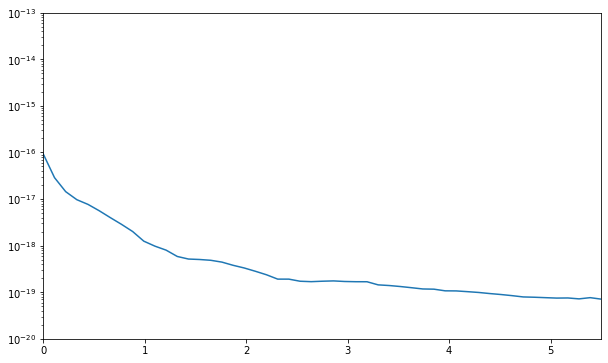

GJ14 02538 F1140C


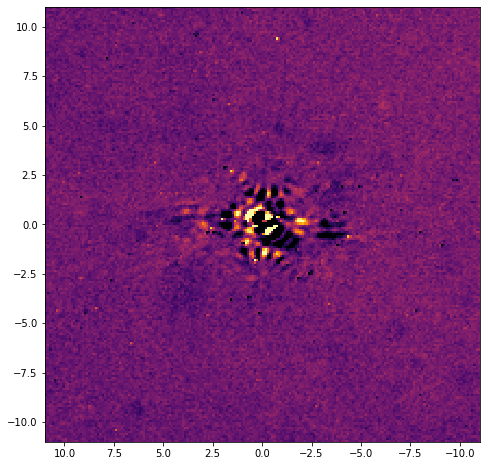

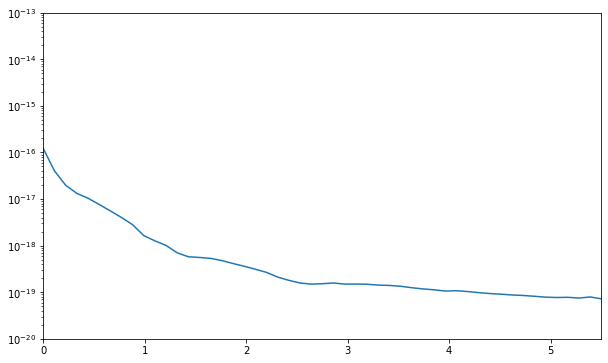

GJ14 02538 F1140C


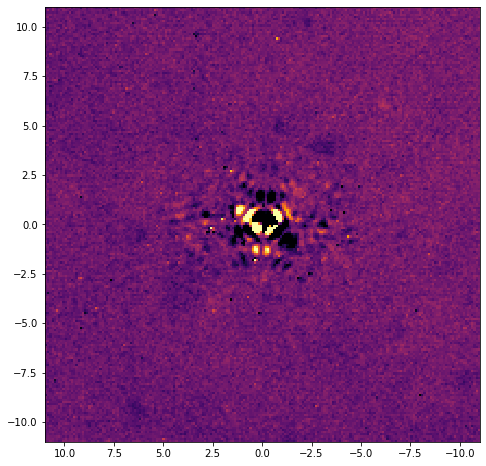

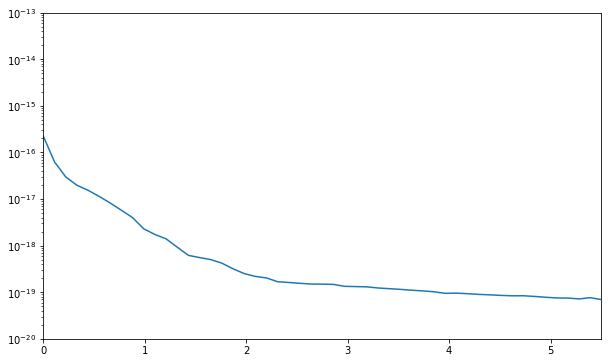

In [ ]:
Y, X = np.ogrid[:200, :200]
x0 = 100
y0 = 100
#### masks for background objects (galaxies, stars)
mask_s1 = np.sqrt((X - x0-20)**2 + (Y-y0+19)**2) > 10
mask_obj = mask_s1

quick_lim_det_miri("HR8799", 1550, 1194, 9, 11, 16, 18, mask_obj, path_d, path_b, path_s)
quick_lim_det_miri("HR8799", 1140, 1194, 8, 12, 15, 19, mask_obj, path_d, path_b, path_s)
quick_lim_det_miri("HR8799", 1065, 1194, 7, 13, 14, 20, mask_obj, path_d, path_b, path_s)


#### masks for background objects (galaxies, stars)
mask_s1 = np.sqrt((X - x0+48)**2 + (Y-y0-22)**2) > 13
mask_obj = mask_s1*0+1.

#1 bkg a traiter séparément
#quick_reduction_miri("beta-pic", 1065, 1241, 28, 26, 29, 31, path_d, path_b, path_s) 
#quick_reduction_miri("beta-pic", 1140, 1241, 27, 25, 30, 32, path_d, path_b, path_s)
quick_lim_det_miri("beta-pic", 1550, 1411, 4, 1, 8, 9, mask_obj, path_d, path_b, path_s)
quick_lim_det_miri("beta-pic", 1550, 1411, 5, 1, 8, 9, mask_obj, path_d, path_b, path_s)
    
#### masks for background objects (galaxies, stars)
mask_s1 = np.sqrt((X - x0-55)**2 + (Y-y0+35)**2) > 10
mask_obj = mask_s1
#HD106906 - utiliser une autre ref
#quick_reduction_miri("HD106906", 1550, 1277, 20, 21, , , path_d, path_b, path_s)
quick_lim_det_miri("HD106906", 1140, 1277, 19, 22, 8, 11, mask_obj, path_d, path_b, path_s)

#### masks for background objects (galaxies, stars)
mask_s1 = np.sqrt((X - x0+35)**2 + (Y-y0-10)**2) > 13
mask_obj = mask_s1

quick_lim_det_miri("HD107146", 1140, 1668, 2, 1, 4, 5, mask_obj, path_d, path_b, path_s)
quick_lim_det_miri("HD107146", 1140, 1668, 3, 1, 4, 5, mask_obj, path_d, path_b, path_s)

#### masks for background objects (galaxies, stars)
mask_s1 = np.sqrt((X - x0+35)**2 + (Y-y0-10)**2) > 13
mask_obj = mask_s1*0+1.

quick_lim_det_miri("HD92945", 1140, 1668, 7, 6, 9, 10, mask_obj, path_d, path_b, path_s)
quick_lim_det_miri("HD92945", 1140, 1668, 8, 6, 9, 10, mask_obj, path_d, path_b, path_s)
 
#### masks for background objects (galaxies, stars)
mask_s1 = np.sqrt((X - x0+35)**2 + (Y-y0-10)**2) > 13
mask_obj = mask_s1*0+1.
    
quick_lim_det_miri("HD206893", 1140, 1668, 12, 11, 14, 15, mask_obj, path_d, path_b, path_s)
quick_lim_det_miri("HD206893", 1140, 1668, 13, 11, 14, 15, mask_obj, path_d, path_b, path_s) 

#### masks for background objects (galaxies, stars)
mask_s1 = np.sqrt((X - x0+35)**2 + (Y-y0-10)**2) > 13
mask_obj = mask_s1*0+1.

quick_lim_det_miri("HD202628", 1140, 2538, 7, 6, 9, 10, mask_obj, path_d, path_b, path_s)
quick_lim_det_miri("HD202628", 1140, 2538, 8, 6, 9, 10, mask_obj, path_d, path_b, path_s)

#### masks for background objects (galaxies, stars)
mask_s1 = np.sqrt((X - x0+35)**2 + (Y-y0-10)**2) > 13
mask_obj = mask_s1*0+1.

quick_lim_det_miri("GJ14", 1140, 2538, 2, 1, 4, 5, mask_obj, path_d, path_b, path_s)
quick_lim_det_miri("GJ14", 1140, 2538, 3, 1, 4, 5, mask_obj, path_d, path_b, path_s)